# Vse: konfliktno prosto barvanje — skupina A, točne metode in gadgeti

Samostojen zvezek za **vse štiri točke projekta 3**. Deluje neodvisno od
`code.ipynb` in `preverjanje.ipynb`; prejšnjih datotek in njihovih dnevnikov ne spreminja.
Vsaka vsebinska vrstica kode ima komentar. Zaženi celice po vrsti v jedru SageMath.

Vsa vozlišča so obarvana. Barvanje ni nujno pravilno. Zahteva za vsako vozlišče
je edinstvena barva v **zaprti** okolici $N[v]=N(v)\cup\{v\}$.
Vsako pravilno barvanje je takšno, zato za ravninske grafe velja
$\chi_{\mathrm{iCFc}}\le4$. Negativen natančni preizkus s tremi barvami zato pri
ravninskem grafu dokazuje vrednost štiri.

Po navodilih že znani rezultati omejujejo najmanjši protiprimer na **13–25 vozlišč**.
To je izhodišče iz literature, ne rezultat našega novega pregleda vseh grafov do 12.
Glavni cilj je manjši protiprimer ali utemeljen negativen rezultat za jasno
opisano podklaso. Izvor: uporabniška navodila in
[Sedlar–Škrekovski](https://arxiv.org/abs/2610.22559).

| Točka | Implementacija |
|---|---|
| 1 | SAT-preizkus, neodvisno preverjanje priče, minimum slabih okolic s SAT in kardinalnostjo, G25 |
| 2 | požrešni pozitivni filter, plantri za 3-povezane grafe, delitev na računalnike, dodajanje vozlišč stopnje 2 |
| 3 | natančni SAT-preizkus prisilnosti, iskanje vseh majhnih povezanih ukoreninjenih gadgetov, pritrjevanje na K4/kolesa in več priključkov |
| 4 | požrešno krčenje, vse končne poti veljavnih izbrisov, ločeno tudi vsi pravi inkluzijski minimumi |

**Izvajanje:** majhni primeri se izvedejo ob običajnem zagonu vseh celic.
Izčrpna iskanja na 13 vozliščih ter velika iskanja gadgetov in minimalnih podgrafov
imajo ločena stikala, privzeto `False`. Izračun vseh teh rezultatov ni predpostavljen
kot že opravljen. Omejeni pregledi vrnejo `popolno=False`.

## 0. Uvozi, neodvisni pregled barvanja in poročanje

`preveri_barvanje` neposredno prešteje barve in vrne slaba vozlišča; ne uporablja
SAT-formulacije. Barve označujemo z `0,1,2` oziroma `0,...,k-1`.
Dnevnik `vse_rezultati.jsonl` je dodajan po vrsticah JSON, brez prepisovanja
prejšnjih zagonov. Zapis grafa vsebuje `n`, `m` in `graph6`; tako ga lahko obnovimo.
Pri gadgetih dodatno shranimo priključka `x,y` v isti normalizaciji oznak.

In [1]:
from operator import index  # Sageova cela števila preverimo brez zaokroževanja.


from pathlib import Path  # Dnevnike shranjujemo na uporabniško določene poti.


from contextlib import ExitStack  # Generatorje pospravimo tudi ob napaki ali prekinitvi.


from datetime import datetime, timezone  # Zagon in zapise označimo z nedvoumnim časom UTC.


from tempfile import TemporaryFile  # Sporočila zunanjih orodij ne smejo zamašiti cevi.


from time import perf_counter  # Trajanje merimo z monotono uro.


from itertools import combinations, permutations  # Naštevamo pare, priključke in vse njihove pritrditve.


from collections import Counter  # Neposredno štejemo barve v zaprtih okolicah.


import subprocess  # Prevedena generatorja povežemo brez ukazne lupine.


import json  # Vsak mejnik zapišemo kot ločen objekt JSON.


import numpy as np  # Pripravimo numerične podatke za rezervni reševalnik.


from scipy.optimize import Bounds, LinearConstraint, milp  # Rezervni HiGHS omogoča preizkuse tudi brez SAT-paketov.


from scipy.sparse import coo_matrix  # Rezervni linearni model hranimo redko.


from sage.all import Graph, graphs, Integer  # Uporabimo Sageove grafe in tip Sageovih celih števil.


from sage.features.nauty import NautyExecutable  # Sage poišče poti do geng in planarg.


def _pozitivno_celo_stevilo(vrednost, ime):  # Enotno preverimo velikosti in dovoljeno število barv.
    if isinstance(vrednost, (bool, np.bool_)):  # Logičnih vrednosti ne obravnavamo kot velikosti.
        raise ValueError(f"{ime} mora biti pozitivno celo število.")  # Pojasnimo napačen argument.
    try:  # Sprejmemo Pythonova in Sageova prava cela števila.
        vrednost = index(vrednost)  # Realnih števil in nizov ne pretvarjamo tiho.
    except TypeError as napaka:  # Napačno vrsto poenotimo v uporabniško napako.
        raise ValueError(f"{ime} mora biti pozitivno celo število.") from napaka  # Ohranimo vzrok.
    if vrednost < 1:  # Nič in negativne vrednosti v tem parametru niso dovoljene.
        raise ValueError(f"{ime} mora biti pozitivno celo število.")  # Ne zaženemo neveljavnega pregleda.
    return vrednost  # Vrnemo preverjeno celo število.


def preveri_barvanje(G, barvanje, k=3):  # Neodvisno vrne vozlišča brez edinstvene barve v zaprti okolici.
    k = _pozitivno_celo_stevilo(k, "k")  # Število dovoljenih barv preverimo pred uporabo.
    if set(barvanje) != set(G):  # Barvanje mora zajeti natanko vsa vozlišča grafa.
        raise ValueError("Barvanje mora določiti barvo vsakega vozlišča.")  # Nepobarvanih vozlišč ne dovolimo.
    if any(index(c) not in range(k) for c in barvanje.values()):  # Barve so oštevilčene od 0 do k-1.
        raise ValueError("Barva ni v dovoljenem obsegu.")  # Napačno pričo zavrnemo.
    slabe = []  # Zbiramo oznake vozlišč, katerih zaprta okolica ni dobra.
    for v in G:  # Pregledamo prav vsako zaprto okolico.
        pojavitve = Counter(barvanje[u] for u in set(G.neighbors(v)) | {v})  # Vozlišče samo vključimo v okolico.
        if 1 not in pojavitve.values():  # Potrebna je vsaj ena barva z natanko eno pojavitvijo.
            slabe.append(v)  # Zapomnimo si kršitev, ne le skupnega števila.
    return slabe  # Prazen seznam pomeni veljavno brezkonfliktno barvanje.


def _kljuc_grafa(G):  # Izomorfne grafe združimo v en razred.
    return G.canonical_label(algorithm="sage").graph6_string()  # Kanonični zapis zajame tudi število vozlišč.


def preveri_plantri():  # Preveri pravo absolutno pot tudi v Pythonovem jedru brez aktiviranega conda PATH.
    from sage.features.graph_generators import Plantri  # Sage pozna imenik programa v svojem okolju.
    try:  # Manjkajočo ali neizvedljivo odvisnost opišemo kot stanje okolja.
        pot = Plantri().absolute_filename()  # Izognemo se iskanju golega imena programa v napačnem PATH.
        preizkus = subprocess.run([pot, "-u", "4"], capture_output=True, text=True, timeout=10)  # Majhen funkcionalni preizkus ne generira datotek.
    except (OSError, RuntimeError, subprocess.TimeoutExpired) as napaka:  # Napaka odvisnosti ni negativen matematični rezultat.
        return {"na_voljo": False, "razlog": str(napaka)}  # Diagnostiko prikažemo pred velikim iskanjem.
    return {"na_voljo": preizkus.returncode == 0, "pot": pot, "diagnostika": preizkus.stderr.strip()}  # O uspehu odloča dejanski zaključni status.


def _json_podatki(vrednost):  # Sageova in NumPyjeva cela števila pretvorimo tudi v gnezdenih podatkih.
    if isinstance(vrednost, (Integer, np.integer)):  # JSON potrebuje Pythonov int namesto Sageovega Integer.
        return int(vrednost)  # Ohranimo natančno celoštevilsko vrednost.
    if isinstance(vrednost, dict):  # Barvanja vsebujejo tudi celoštevilske ključe vozlišč.
        return {_json_podatki(k): _json_podatki(v) for k, v in vrednost.items()}  # Pretvorimo ključe in vrednosti.
    if isinstance(vrednost, (list, tuple)):  # Seznami grafov in slabih vozlišč so lahko gnezdeni.
        return [_json_podatki(v) for v in vrednost]  # Zaporedja v JSON predstavimo kot polja.
    return vrednost  # Druge vrste prepustimo običajnemu preverjanju kodirnika JSON.


def zapisi_porocilo(tip, pot="vse_rezultati.jsonl", **podatki):  # Rezultat ali mejnik dodamo v skupni dnevnik.
    zapis = {"tip": tip, "cas_utc": datetime.now(timezone.utc).isoformat(), **podatki}  # Zapis je samostojno razumljiv.
    vrstica = json.dumps(_json_podatki(zapis), ensure_ascii=False) + "\n"  # Celoten zapis preverimo pred odpiranjem dnevnika.
    with Path(pot).open("a", encoding="utf-8") as datoteka:  # Obstoječih rezultatov ne prepišemo.
        datoteka.write(vrstica)  # Ena vrstica predstavlja en objekt JSON.
        datoteka.flush()  # Mejnik je takoj viden drugim bralcem datoteke.


def zapisi_grafe(tip, grafi, pot="vse_rezultati.jsonl", **podatki):  # Shranimo grafe skupaj z razlago eksperimenta.
    zapisi_porocilo(tip, pot, grafi=[{"n": G.order(), "m": G.size(), "graph6": G.graph6_string()} for G in grafi], **podatki)  # graph6 omogoča obnovitev.


def zapisi_gadgete(tip, gadgeti, pot="vse_rezultati.jsonl", **podatki):  # Gadget potrebuje tudi označeni priključni rob, ne le abstraktnega grafa.
    zapisi = []  # Pripravimo popolne zapise ukoreninjenih rezultatov.
    for gadget in gadgeti:  # Vsak najdeni graf ima svoja dejanska priključka x in y.
        H = gadget["graf"]  # Vhodnega objekta ne spreminjamo pri preimenovanju oznak.
        oznake = {v: i for i, v in enumerate(H)}  # Oznake normaliziramo, da bo graph6 ohranil povezavo s korenoma.
        C = H.relabel(oznake, inplace=False)  # Novo kopijo z zaporednimi oznakami lahko nedvoumno obnovimo.
        zapisi.append({"graph6": C.graph6_string(), "x": oznake[gadget["x"]], "y": oznake[gadget["y"]], "notranjih": H.order()-2})  # Shranimo korena iste normalizacije.
    zapisi_porocilo(tip, pot, gadgeti=zapisi, **podatki)  # Poročilo omogoča ponovitev prisilnega testa točno tega roba.


## 1a. Točna odločitev s SAT

Za vsako vozlišče in barvo sta spremenljivki `x[v,c]` (dodelitev barve) ter
`y[v,c]` (izbrana edinstvena barva okolice). Vsako vozlišče dobi natanko eno barvo.
Vsaka okolica izbere vsaj eno pričo `y`; ta zahteva vsaj eno in največ eno pojavitev.
To ne zahteva različnih barv na sosedih. Fiksiranje prve barve na 0 odstrani
samo simetrijo imen barv.

`resi_cnf` vrne slovar logičnih vrednosti ali `None` za dokazani UNSAT; napaka ali
neodločenost ostane izjema. Prednost imata PySAT/Glucose in PicoSAT; rezervni
HiGHS rešuje isto SAT-formulo kot binarni linearni model za manjše preizkuse.
Pozitivni model preverimo po klavzulah in še po dejanskih okolicah.

In [2]:
from importlib.util import find_spec  # Preverimo razpoložljivost hitrih SAT-paketov brez samodejnega nameščanja.


def izbrani_backend(backend="auto"):  # Izberemo nameščeni SAT-reševalnik ali obstoječi HiGHS za manjše preizkuse.
    if backend not in ("auto", "pysat", "picosat", "highs"):  # Neznana imena zavrnemo, da se ne bi tiho uporabil drug reševalnik.
        raise ValueError("backend mora biti auto, pysat, picosat ali highs.")  # Uporabniku navedemo dovoljene možnosti.
    if backend == "auto":  # Samodejna izbira daje prednost pravemu SAT-reševalniku.
        return "pysat" if find_spec("pysat") else "picosat" if find_spec("pycosat") else "highs"  # HiGHS je rezervna možnost.
    if backend == "pysat" and not find_spec("pysat"):  # Izrecno zahtevanega manjkajočega paketa ne nadomestimo na skrivaj.
        raise RuntimeError("Za backend='pysat' namesti paket python-sat v izbrano jedro.")  # Sporočilo navede pravo ime paketa.
    if backend == "picosat" and not find_spec("pycosat"):  # Enako preverimo paket PicoSATovega Pythonovega vmesnika.
        raise RuntimeError("Za backend='picosat' namesti paket pycosat v izbrano jedro.")  # Namestitev ostane odločitev uporabnika.
    return backend  # Pri izrecni veljavni izbiri ohranimo željo uporabnika.


def resi_cnf(klavzule, nvars, backend="auto"):  # Vrne popolno logično prireditev ali None samo za dokazani UNSAT.
    backend = izbrani_backend(backend)  # Pred gradnjo modela preverimo zahtevani reševalnik.
    nvars = index(nvars)  # Število spremenljivk mora biti celo število, dovoljeno je tudi nič.
    if nvars < 0:  # Negativna dimenzija nima pomena.
        raise ValueError("nvars mora biti nenegativen.")  # Napake vhodnih podatkov ločimo od neizpolnljivosti.
    klavzule = [tuple(index(lit) for lit in C) for C in klavzule]  # Literale shranimo kot preverjena cela števila.
    if any(lit == 0 or abs(lit) > nvars for C in klavzule for lit in C):  # SAT uporablja indekse od 1 do nvars.
        raise ValueError("Literal ni v dovoljenem obsegu 1..nvars.")  # Ničla je v DIMACS zaključek, ne spremenljivka.
    if any(not C for C in klavzule):  # Prazna disjunkcija ne more biti resnična.
        return None  # Prisotnost ene prazne klavzule že dokaže neizpolnljivost formule.
    if not klavzule:  # Prazna konjunkcija je izpolnljiva tudi brez spremenljivk.
        return {i: False for i in range(1, nvars + 1)}  # Poljubna popolna prireditev tedaj zadostuje.
    if backend == "pysat":  # Ta veja uporablja pravi inkrementalni SAT-vmesnik, tukaj za en sam klic.
        from pysat.solvers import Solver  # Uvoz izvedemo samo, kadar je paket na voljo in izbran.
        with Solver(name="glucose3", bootstrap_with=klavzule) as S:  # Kontekst zagotovi sprostitev pomnilnika reševalnika.
            odgovor = S.solve()  # Odgovor obravnavamo ločeno od njegove logične pretvorbe.
            if odgovor is None:  # Neodločen odgovor ne sme postati dokaz neizpolnljivosti.
                raise RuntimeError("PySAT ni odločil o formuli.")  # Pregled ne sme poročati lažnega protiprimera.
            if odgovor is False:  # Samo izrecni False pomeni dokazani UNSAT.
                return None  # Negativni rezultat vrnemo brez sestavljanja barvanja.
            if odgovor is not True:  # Zaščitimo se tudi pred nepričakovanim odzivom vmesnika.
                raise RuntimeError("PySAT je vrnil neznan odgovor.")  # Napačnega statusa ne pretvorimo v pozitiven model.
            pozitivni = {lit for lit in S.get_model() if lit > 0}  # Iz modela preberemo resnične spremenljivke.
        model = {i: i in pozitivni for i in range(1, nvars + 1)}  # Neuporabljene spremenljivke dopolnimo z False.
    elif backend == "picosat":  # Alternativna hitra SAT-izvedba je dostopna prek paketa pycosat.
        import pycosat  # Odvisnost potrebujemo samo za to vejo.
        odgovor = pycosat.solve(klavzule, vars=nvars)  # PicoSAT neposredno prejme klavzule CNF.
        if odgovor == "UNSAT":  # Samo ta eksplicitni odgovor pomeni neizpolnljivost.
            return None  # Vrnjeni None je enoten negativen odgovor vseh zaledij.
        if odgovor == "UNKNOWN":  # Neodločen odgovor ni dokaz, da barvanje ne obstaja.
            raise RuntimeError("PicoSAT ni odločil o formuli.")  # Pregled se ustavi z jasno napako.
        pozitivni = {lit for lit in odgovor if lit > 0}  # Pozitivni predznačeni indeksi predstavljajo True.
        model = {i: i in pozitivni for i in range(1, nvars + 1)}  # Vrnemo isti tip modela kot v drugih vejah.
    else:  # HiGHS lahko reši CNF prek binarnega linearnega modela; za velike preglede uporabimo SAT.
        rr, cc, dd, spodnje = [], [], [], []  # Redko matriko sestavimo brez ustvarjanja gostih ničelnih blokov.
        for r, C in enumerate(klavzule):  # Ena SAT-klavzula postane ena linearna neenačba.
            spodnje.append(1 - sum(lit < 0 for lit in C))  # Negativni literal pomeni 1-x, zato prestavimo konstante.
            for lit in C:  # Vsak literal prispeva en koeficient v ustreznem stolpcu.
                rr.append(r)  # Indeks vrstice označi trenutno klavzulo.
                cc.append(abs(lit) - 1)  # SATov 1-osnovani indeks pretvorimo v NumPyjev 0-osnovani indeks.
                dd.append(1.0 if lit > 0 else -1.0)  # Predznak koeficienta sledi predznaku literala.
        A = coo_matrix((dd, (rr, cc)), shape=(len(klavzule), nvars)).tocsc()  # Podvojeni stolpci se pravilno seštejejo.
        rezultat = milp(  # Dopustnost iste CNF-formule preverimo s HiGHS.
            np.zeros(nvars), integrality=np.ones(nvars, dtype=int), bounds=Bounds(0, 1),  # Spremenljivke so binarne.
            constraints=LinearConstraint(A, spodnje, np.inf),  # Vsaka disjunkcija mora imeti vsaj en resničen literal.
        )  # Brez časovne omejitve se neodločenost ne zamenja z negativnim odgovorom.
        if rezultat.status == 2:  # HiGHS je linearni binarni model dokazal kot nedopusten.
            return None  # To je edini status, ki pomeni UNSAT.
        if rezultat.status != 0 or rezultat.x is None:  # Napake, prekinitve in omejitve niso negativni dokazi.
            raise RuntimeError(f"HiGHS ni odločil o formuli: {rezultat.message}")  # Ne vrnemo lažnega protiprimera.
        model = {i + 1: bool(x > 0.5) for i, x in enumerate(rezultat.x)}  # Numerično rešitev pretvorimo v logično.
    if not all(any(model[abs(lit)] == (lit > 0) for lit in C) for C in klavzule):  # Preverimo dejanske klavzule.
        raise RuntimeError("Reševalnik je vrnil model, ki ne izpolni CNF.")  # Napačnega pozitivnega modela ne sprejmemo.
    return model  # Izpolnljiva formula ima preverjeno popolno prireditev vseh deklariranih spremenljivk.


def cnf_barvanje(G, k=3, dovoljene_slabe=False):  # Sestavimo skupno osnovo za odločanje in optimizacijo zaprtih okolic.
    k = _pozitivno_celo_stevilo(k, "k")  # Barv mora biti pozitivno celo število.
    if G.is_directed() or G.has_loops() or G.has_multiple_edges():  # Naloga uporablja enostavne neusmerjene grafe.
        raise ValueError("Pričakovan je enostaven neusmerjen graf.")  # Druge vrste vhodov nimajo dogovorjene interpretacije.
    vozlisca, klavzule = list(G), []  # Zaporedje vozlišč ohrani izvirne oznake, klavzule gradimo sproti.
    x, y, slabe = {}, {}, {}  # Preslikave omogočajo razlago modela in dodatne omejitve za gadgete.
    stevec = 0  # SAT-spremenljivke bomo številčili od 1 dalje.
    for v in vozlisca:  # Najprej rezerviramo spremenljivke dodelitve barv in edinstvenih barv.
        for c in range(k):  # Vsakemu vozlišču in vsaki barvi pripadata dva binarna podatka.
            stevec += 1  # Naslednji prosti indeks namenimo dodelitvi barve.
            x[v, c] = stevec  # x(v,c) pomeni, da v dobi barvo c.
            stevec += 1  # Naslednji indeks namenimo priči edinstvenosti.
            y[v, c] = stevec  # y(v,c) pomeni, da je c izbrana edinstvena barva v N[v].
        if dovoljene_slabe:  # Optimizacijski model lahko dovoli kršitev pogoja posamezne okolice.
            stevec += 1  # Dodatna spremenljivka omogoči izklop zahteve po priči za to vozlišče.
            slabe[v] = stevec  # True pomeni dovoljeno slabo okolico, kar pozneje omejimo s kardinalnostjo.
        klavzule.append(tuple(x[v, c] for c in range(k)))  # Vsako vozlišče mora dobiti vsaj eno barvo.
        for c, d in combinations(range(k), 2):  # Izločimo možnost dveh različnih barv na istem vozlišču.
            klavzule.append((-x[v, c], -x[v, d]))  # Skupaj s prejšnjo klavzulo dobimo natanko eno barvo.
    if vozlisca:  # Simetrijo poimenovanja barv odstranimo le, če prvo vozlišče obstaja.
        klavzule.append((x[vozlisca[0], 0],))  # V poljubnem barvanju lahko barvo prvega vozlišča preimenujemo v 0.
    for v in vozlisca:  # Za vsako zaprto okolico uveljavimo obstoj edinstvene barve.
        N = list(set(G.neighbors(v)) | {v})  # Zaprta okolica vsebuje vse sosede in vozlišče samo.
        prica = tuple(y[v, c] for c in range(k))  # Vsaj eno barvo želimo izbrati kot edinstveno.
        klavzule.append(prica + ((slabe[v],) if dovoljene_slabe else ()))  # Slaba okolica je dovoljena samo v optimizaciji.
        for c in range(k):  # Vsaka možna priča dobi implikacijo na število pojavitev barve.
            klavzule.append((-y[v, c],) + tuple(x[u, c] for u in N))  # Izbrana edinstvena barva se mora pojaviti vsaj enkrat.
            for u, w in combinations(N, 2):  # Po parih prepovemo dve pojavitvi iste izbrane barve.
                klavzule.append((-y[v, c], -x[u, c], -x[w, c]))  # Pri y=True se barva c ne sme pojaviti na obeh vozliščih.
    return {"klavzule": klavzule, "nvars": stevec, "x": x, "y": y, "slabe": slabe}  # Vrnemo tudi podatke za razlago modela.


def _preberi_barvanje(G, formula, model, k):  # Model SAT pretvorimo v barve z izvirnimi oznakami vozlišč.
    barvanje = {}  # Barvanje bo slovar, ne seznam, zato so dovoljene tudi neštevilske oznake.
    for v in G:  # Preverimo tudi, da vsak v dobi natanko eno resnično spremenljivko x.
        izbrane = [c for c in range(k) if model[formula["x"][v, c]]]  # Priče y ne določajo barve vozlišča.
        if len(izbrane) != 1:  # Napačno večkratno ali manjkajočo barvo obravnavamo kot napako modela.
            raise RuntimeError("Model ne določa natanko ene barve na vozlišče.")  # Ne vračamo neveljavnega barvanja.
        barvanje[v] = izbrane[0]  # Ohranimo edino dodeljeno barvo tega vozlišča.
    return barvanje  # Pozneje ga neposredno preverimo na okolici v grafu.


def je_brezkonfliktno_k_obarvljiv(G, k=3, backend="auto"):  # Odločimo o obstoju polnega brezkonfliktnega k-barvanja.
    formula = cnf_barvanje(G, k)  # V običajnem modelu slabe okolice niso dovoljene.
    model = resi_cnf(formula["klavzule"], formula["nvars"], backend)  # Samo UNSAT pomeni, da barvanje ne obstaja.
    if model is None:  # Negativni rezultat je dokazano neizpolnljiva natančna formulacija.
        return False  # Uporabniku vrnemo logično neobarvljivost.
    barvanje = _preberi_barvanje(G, formula, model, k)  # Iz pozitivne rešitve sestavimo konkretno dodelitev barv.
    if preveri_barvanje(G, barvanje, k):  # Neodvisno preštejemo barve v dejanskih zaprtih okolicah.
        raise RuntimeError("Reševalnik je vrnil barvanje s slabo zaprto okolico.")  # Napačnega pozitivnega odgovora ne sprejmemo.
    return True  # Model in neposredno preverjanje potrjujeta veljavno barvanje.


### Preverjanje odvisnosti in način namestitve

Za načrtovani veliki pregled uporabi namenski SAT in `plantri`. Trenutne poti
izpiše spodnja celica; če je bilo kaj nameščeno med že odprto sejo, ponovno zaženi jedro.
Ta zvezek sam ne zaganja namestitvenih ukazov.

SAT v Sageovem terminalu: `sage -pip install python-sat` (ali `pycosat`).
Pri okolju conda uporabi **Python iz tega okolja** z `-m pip install python-sat`.
Za plantri preveri `preveri_plantri()` spodaj; distribucijski Sage lahko
uporabi `sage -i plantri`. Pri conda različici namesti prevedeni program `plantri`
v imenik `bin` aktivnega Sageovega okolja. Če prevedeš vir, uporabi uradni
[plantri](https://users.cecs.anu.edu.au/~bdm/plantri/) ali Sageov arhiv in preveri
kontrolni seštevek. Ne zamenjuj tega programa z generatorjem samo triangulacij.

In [3]:
from sage.features.graph_generators import Plantri  # Preverimo prav tisti program, ki ga uporablja Sage.
print("Izbrano SAT-zaledje:", izbrani_backend())  # Za veliko iskanje naj bo izpis pysat ali picosat.
print("Plantri:", preveri_plantri())  # Absolutna pot deluje tudi, če conda bin ni na PATH trenutnega jedra.
from importlib.metadata import version  # V dnevnik vključimo nameščene različice zaradi ponovljivosti meritev.
import sys  # Izpišemo tudi različico Pythona v izbranem jedru.
zapisi_porocilo("okolje", python=sys.version.split()[0], scipy=version("scipy"), sat=izbrani_backend(), pysat=version("python-sat") if find_spec("pysat") else None, plantri=preveri_plantri())  # Okolje je del poročila vsakega zagona.
if izbrani_backend() == "highs":  # Rezervni način ostane matematično pravilen, a manj primeren za milijone preizkusov.
    print("HiGHS je rezervni način; pred velikim iskanjem namesti namenski SAT.")  # Jasno ločimo uporabnost od hitrosti.


Izbrano SAT-zaledje: pysat
Plantri: {'na_voljo': True, 'pot': '/home/sawdem/miniforge3/envs/sage/bin/plantri', 'diagnostika': '/home/sawdem/miniforge3/envs/sage/bin/plantri -u 4 \n1 triangulations generated; cpu=0.00 sec'}


## 1b. Minimum slabih okolic za skupino B

Želimo $\min_c |\{v:N[v]\text{ nima edinstvene barve pri }c\}|$ med **vsemi polnimi
3-barvanji**. To ni isto kot najmanjše število nepobarvanih vozlišč.
Dodamo zastavico `z[v]`: okolica izbere pričo ali se sprosti z `z[v]=True`.
Omejitev »največ `t` zastavic« kodiramo s sekvenčnim števcem v $O(nt)$;
ne uporabljamo eksponentnega naštevanja vseh $(t+1)$-podmnožic.

Dopustnost je monotona po `t`, zato uporabimo binarno iskanje meje. Ob vsakem
pozitivnem odgovoru neposredno preštejemo dejansko slaba vozlišča. Končni rezultat
vsebuje `minimum`, konkretno `barvanje` in `slaba_vozlisca`. Če je minimum 0,
je graf brezkonfliktno 3-obarvljiv. To je SAT s kardinalnostjo, ne počasnejša
ILP-optimizacija ciljne funkcije; samo rezervno zaledje lahko SAT rešuje s HiGHS.
[O kardinalnostnih kodiranjih](https://pysathq.github.io/docs/html/api/card.html).

In [4]:
def najvec_t(spremenljivke, t, nvars):  # Sekvenčni števec v O(n*t) kodira omejitev največ t resničnih spremenljivk.
    spremenljivke, t = list(spremenljivke), index(t)  # Zaporedje porabimo enkrat, meja mora biti celoštevilska.
    if t < 0:  # Negativno dovoljeno število True je nemogoče.
        return [()], nvars  # Prazna klavzula predstavlja dokazano nedopustno mejo.
    if t >= len(spremenljivke):  # Meja nad številom spremenljivk ne omejuje nobene prireditve.
        return [], nvars  # Dodatne spremenljivke in klavzule niso potrebne.
    if t == 0:  # Poseben primer lahko kodiramo linearno brez pomožnih spremenljivk.
        return [(-x,) for x in spremenljivke], nvars  # Vsaka vhodna spremenljivka mora biti False.
    C, s = [], {}  # s(i,j) bo pomenil, da je v prvih i vhodih vsaj j resničnih vrednosti.
    for i, x in enumerate(spremenljivke, 1):  # Predpone vhodnega zaporedja gradimo od leve proti desni.
        for j in range(1, min(i, t) + 1):  # Pragovi višji od i ali dovoljene meje niso potrebni.
            nvars += 1  # Vsak prag dobi svežo pomožno spremenljivko.
            s[i, j] = nvars  # Pomožni indeksi ne smejo trčiti z indeksi osnovnega modela.
        C.append((-x, s[i, 1]))  # Resničen trenutni vhod zagotovi vsaj en True v trenutni predponi.
        for j in range(1, min(i - 1, t) + 1):  # Doseženi pragovi iz prejšnje predpone ostanejo doseženi.
            C.append((-s[i - 1, j], s[i, j]))  # To je implikacija s(i-1,j) => s(i,j).
        for j in range(2, min(i, t) + 1):  # Dodani True poviša prejšnji doseženi prag za ena.
            C.append((-x, -s[i - 1, j - 1], s[i, j]))  # x AND s(i-1,j-1) => s(i,j).
        if i > t:  # Ko je bilo prej že doseženih t pojavitev, naslednji True povzroči preliv.
            C.append((-x, -s[i - 1, t]))  # Prepovemo prav t+1-to resnično vrednost.
    return C, nvars  # Vrnemo klavzule števca in največji porabljeni SAT-indeks.


def min_slabe_okolice(G, backend="auto"):  # Izračunamo minimum slabih zaprtih okolic med vsemi polnimi 3-barvanji.
    formula = cnf_barvanje(G, 3, dovoljene_slabe=True)  # Vsako okolico lahko izjemoma sprostimo s spremenljivko z(v).
    slabe_spremenljivke = list(formula["slabe"].values())  # Samo te spremenljivke šteje omejitev največ t.
    najboljsi = {v: 0 for v in G}  # Enobarvno barvanje je dovoljena začetna rešitev za optimizacijo, ne nujno brezkonfliktna.
    najmanj, najvec = 0, len(preveri_barvanje(G, najboljsi, 3))  # Začetna zgornja meja je dejanski rezultat tega barvanja.
    while najmanj < najvec:  # Dopustnost meje t je monotona, zato lahko uporabimo binarno iskanje.
        t = (najmanj + najvec) // 2  # Preizkusimo sredino še neodločenega intervala optimalnih vrednosti.
        dodatne, nvars = najvec_t(slabe_spremenljivke, t, formula["nvars"])  # Osnovnemu modelu dodamo sekvenčno omejitev.
        model = resi_cnf(formula["klavzule"] + dodatne, nvars, backend)  # To ostaja SAT-preizkus, ne ILP-optimizacijska funkcija.
        if model is None:  # Nobeno 3-barvanje nima največ t slabih okolic.
            najmanj = t + 1  # Optimalna vrednost mora biti večja od dokazane nemogoče meje.
        else:  # Dopustna rešitev poda konkretno boljšo zgornjo mejo.
            najboljsi = _preberi_barvanje(G, formula, model, 3)  # Iz SAT-modela preberemo celotno 3-barvanje.
            dejansko_slabe = preveri_barvanje(G, najboljsi, 3)  # Štejemo dejanske slabe okolice, ne le sprostitvenih zastavic.
            if len(dejansko_slabe) > t:  # Tak rezultat bi pomenil napako kodiranja ali reševalnika.
                raise RuntimeError("Vrnjeno barvanje krši omejitev največ t slabih okolic.")  # Napake ne skrijemo kot slabši optimum.
            najvec = len(dejansko_slabe)  # Boljši dejanski rezultat lahko interval skrči močneje od same meje t.
    slaba_vozlisca = preveri_barvanje(G, najboljsi, 3)  # Vrnjeni seznam vsebuje izvirne oznake problematičnih vozlišč.
    if len(slaba_vozlisca) != najmanj:  # Zgornja in spodnja meja morata ob zaključku sovpadati tudi z vrnjeno pričo.
        raise RuntimeError("Optimalna vrednost in vrnjeno barvanje se ne ujemata.")  # To varuje pravilnost poročila skupini B.
    return {"minimum": najmanj, "barvanje": najboljsi, "slaba_vozlisca": slaba_vozlisca}  # Vrnemo optimum in pričo zanj.


## 1c. G25: obnovitev, preverjanje, ocena za skupino B in izris

Zapis graph6 iz PDF vsebuje tipografske znake; v programski različici spodaj je
ASCII znak **backtick** za `~` in navaden `_`. Funkcija preveri 25 vozlišč,
55 povezav, povezanost in ravninskost. Negativen odgovor za tri in pozitiven za
štiri barve neodvisno potrdita $\chi_{\mathrm{iCFc}}=4$.
Izris uporabimo neposredno kot PNG v izhodu Jupyterja, zato ni odvisen od
Sageove privzete nastavitve zunanjega prikazovalnika.

In [5]:
G25_GRAPH6 = "X~`EERMg@?C?_CgFG?A??O?LO?u??A??B???_??e??FK???K??@"  # Uporabimo navaden ASCII backtick, ne tipografske navednice iz PDF.


def protiprimer_25():  # Obnovi isti graf iz uradnega zapisa graph6.
    G = Graph(G25_GRAPH6, format="graph6")  # graph6 neposredno kodira vse povezave.
    if G.order() != 25 or G.size() != 55 or not G.is_connected() or not G.is_planar():  # Preverimo prepis in osnovne lastnosti.
        raise RuntimeError("Zapis G25 ni ustrezen.")  # Napačne tipografske znake odkrijemo takoj.
    return G  # Sestavljanje ne zahteva nobenega iskanja drugih grafov.


G25: n=25, m=55, χiCFc=4; minimum slabih okolic pri treh barvah: 1
Čas preizkusa in optimizacije: 0.064 s


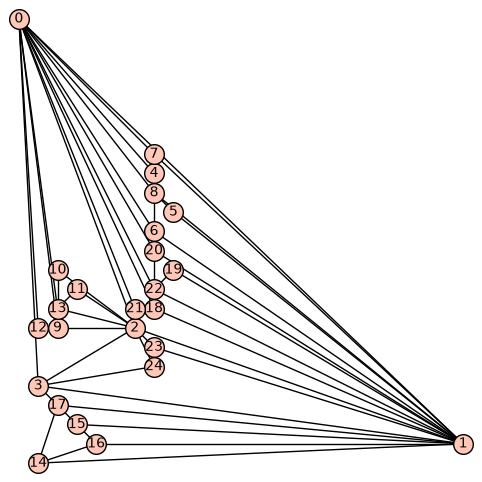

In [6]:
G25 = protiprimer_25()  # Obnovimo uradni primer neposredno iz zapisa graph6.
zacetek_25 = perf_counter()  # Ločeno izmerimo celotni preizkus in optimizacijo znanega primera.
assert not je_brezkonfliktno_k_obarvljiv(G25, 3)  # To je natančen dokaz neobstoja ustreznega 3-barvanja.
assert je_brezkonfliktno_k_obarvljiv(G25, 4)  # Preverimo tudi dosegljivost zgornje meje.
ocena_25 = min_slabe_okolice(G25)  # Skupina B dobi najmanjše možno število slabih zaprtih okolic in pričo.
zapisi_grafe("G25", [G25], minimum=ocena_25["minimum"], slaba_vozlisca=ocena_25["slaba_vozlisca"], barvanje=ocena_25["barvanje"], backend=izbrani_backend())  # Shranimo preverjene rezultate.
print("G25: n=25, m=55, χiCFc=4; minimum slabih okolic pri treh barvah:", ocena_25["minimum"])  # Poročamo dejansko izračunano vrednost.
print("Čas preizkusa in optimizacije:", round(perf_counter()-zacetek_25, 3), "s")  # Čas je meritev tega okolja.
from io import BytesIO  # Sliko shranimo v pomnilnik, brez odpiranja zunanjega programa.
from IPython.display import Image, display  # Izrecno objavimo sliko v izhodni celici zvezka.
from matplotlib import pyplot as plt  # Po prikazu figuro sprostimo.
figura = G25.plot(layout="planar", vertex_labels=True).matplotlib(figsize=8)  # Uporabimo preverjeno ravninsko postavitev.
with BytesIO() as slika:  # Pomnilniški medpomnilnik se ob izhodu sam zapre.
    figura.savefig(slika, format="png", bbox_inches="tight")  # Risbo pretvorimo v PNG.
    display(Image(data=slika.getvalue()))  # Slika se pojavi neposredno pod celico.
plt.close(figura)  # Zapremo figure, katerih slika je že poslana v zvezek.


## 2a. Hiter filter in tokovni pregled z verodostojnim poročilom

Najprej poskusimo požrešno **pravilno** barvanje z največ tremi barvami. Njegov
uspeh že dokaže zahtevano lastnost; neuspeh ni dokaz neobarvljivosti, zato takrat
vedno pokličemo SAT. Poročilo šteje uspehe filtra, dokončne SAT-klice in vse
odločene grafe. Izjema ne poveča števca nedokončanega SAT-klica.

`preglej_druzino` vrne tudi objekte `neobarvljivi`. Zapis protiprimera nastane
takoj, napredek vsakih `korak` primerov, zaključek tudi ob običajnem `Interrupt`.
`max_grafov` je označen poskusni limit, ne dokaz za celotno podklaso. Privzeto
ni limita. Družino poimenuj natančno, z velikostjo, podklaso in delom `res/mod`.

In [7]:
def hitro_barvanje(G, k=3):  # Hiter požrešni filter sme potrditi barvanje, nikoli pa neobarvljivosti.
    k = _pozitivno_celo_stevilo(k, "k")  # Barv ne spreminjamo glede na uspeh hevristike.
    barvanje = {}  # Sestavljamo polno pravilno barvanje, ki bo tudi brezkonfliktno.
    vrstni_red = sorted(G, key=lambda v: G.degree(v), reverse=True)  # Najprej obravnavamo vozlišča z največ sosedi.
    for v in vrstni_red:  # Vsako vozlišče dobi barvo samo enkrat.
        zasedene = {barvanje[u] for u in G.neighbors(v) if u in barvanje}  # Upoštevamo že obarvane sosede.
        prosta = next((c for c in range(k) if c not in zasedene), None)  # Izberemo prvo še dovoljeno barvo.
        if prosta is None:  # Požrešni neuspeh ne dokazuje, da brezkonfliktno barvanje ne obstaja.
            return None  # Tak graf mora dobiti natančni SAT-preizkus.
        barvanje[v] = prosta  # Pozitivni rezultat ostane pravilno barvanje dosedanjega podgrafa.
    if preveri_barvanje(G, barvanje, k):  # Preverimo matematični pogoj še neposredno.
        raise RuntimeError("Požrešni filter je vrnil neveljavno pričo.")  # Napačne potrditve ne dovolimo.
    return barvanje  # Uspešna priča omogoči preskok dragega SAT-klica.


def preglej_druzino(grafi, oznaka, backend="auto", pot="vse_rezultati.jsonl", korak=10000, max_grafov=None):  # Tokovno pregleda podano razredčeno ali polno družino.
    korak = _pozitivno_celo_stevilo(korak, "korak")  # Zapisovanje ne sme imeti ničelnega intervala.
    if max_grafov is not None:  # None izrecno pomeni pregled do izčrpanja iteratorja.
        max_grafov = _pozitivno_celo_stevilo(max_grafov, "max_grafov")  # Omejitev je uporabna za označene poskusne zagone.
    backend = izbrani_backend(backend)  # Izbrano zaledje zapišemo v poročilo zaradi ponovljivosti.
    zagon = datetime.now(timezone.utc).isoformat()  # Vsi mejniki tega pregleda delijo isto oznako zagona.
    zacetek, pregledanih, hitro, sat = perf_counter(), 0, 0, 0  # Posebej merimo oba načina odločanja.
    protiprimeri, stanje = [], "napaka"  # Nepopolnega dela nikoli ne označimo kot dokončano.
    def povzetek():  # V vsakem trenutku pripravimo enak nabor števcev.
        return dict(zagon=zagon, oznaka=oznaka, backend=backend, pregledanih=pregledanih, hitro=hitro, sat=sat, neobarvljivih=len(protiprimeri), sekund=perf_counter()-zacetek)  # SAT šteje samo dokončane SAT-preizkuse.
    with ExitStack() as sklad:  # Poskrbimo tudi za zapiranje zunanjih generatorjev.
        iterator = iter(grafi)  # Celotne družine ne pretvarjamo v seznam.
        zapri = getattr(iterator, "close", None)  # Seznam nima zunanjih procesov; generator jih lahko ima.
        if callable(zapri):  # Registriramo samo podprto zapiranje.
            sklad.callback(zapri)  # Tudi prekinitev uporabnika ustavi proces generatorja.
        zapisi_porocilo("zacetek", pot, max_grafov=max_grafov, **povzetek())  # Parametri ostanejo zapisani pred prvim grafom.
        try:  # Končni mejnik mora nastati tudi po napaki ali običajni prekinitvi.
            while True:  # Iterator porabljamo, dokler se ne izčrpa ali dosežemo dogovorjeno mejo.
                if max_grafov is not None and pregledanih >= max_grafov:  # Mejo preverimo pred generiranjem naslednjega kandidata.
                    stanje = "omejeno"  # Tak rezultat je delni tudi, če bi bil naslednji klic že konec iteratorja.
                    break  # Ne trdimo, da je bila celotna družina izčrpana.
                try:  # Izčrpanje toka je normalen konec polnega pregleda.
                    G = next(iterator)  # V pomnilniku obdržimo le trenutni graf in protiprimere.
                except StopIteration:  # Generator je potrdil normalen zaključek svoje celotne družine.
                    stanje = "koncano"  # Le ta pot upravičuje oznako popolnega pregleda.
                    break  # Preidemo na zaključni mejnik.
                prica = hitro_barvanje(G, 3)  # Najprej poskusimo poceni pozitivni filter.
                if prica is not None:  # Preverjena požrešna priča že dokaže 3-obarvljivost.
                    obarvljiv = True  # SAT-klic za ta graf ni potreben.
                    hitro += 1  # Štejemo uspehe filtra, ne njegovih neuspelih poskusov.
                else:  # Samo preostale grafe pošljemo natančnemu postopku.
                    obarvljiv = je_brezkonfliktno_k_obarvljiv(G, 3, backend)  # Neodločen rezultat sproži izjemo.
                    sat += 1  # Nedokončanega SAT-klica ne štejemo med odločene.
                pregledanih += 1  # Števec povečamo šele po dokončni odločitvi za graf.
                if not obarvljiv:  # Najdeni negativni primer želimo tudi kasneje rekonstruirati.
                    if not G.is_planar():  # Pri tujih iteratorjih posebej preverimo podlago za sklep o štirih barvah.
                        raise ValueError("Družina vsebuje neravninski negativni primer.")  # Tega ne razglasimo za ravninski protiprimer.
                    protiprimeri.append(G)  # Vrnili bomo dejanske Sageove objekte.
                    zapisi_grafe("protiprimer", [G], pot, **povzetek())  # Strukturo shranimo takoj, brez čakanja na mejnik.
                if pregledanih % korak == 0:  # Konzole in datoteke ne obremenjujemo pri vsakem grafu.
                    zapisi_porocilo("napredek", pot, **povzetek())  # Zapišemo točno število že odločenih primerov.
        except KeyboardInterrupt:  # Ročna prekinitev ne pomeni končanega izčrpnega pregleda.
            stanje = "prekinjeno"  # V dnevniku ostane jasna oznaka nepopolnosti.
            raise  # Uporabnik v zvezku vidi običajno prekinitev.
        except Exception as napaka:  # Sem sodijo tudi napake generatorjev in reševalnikov.
            stanje = f"napaka: {type(napaka).__name__}: {napaka}"  # Napako opišemo tudi v trajnem dnevniku.
            raise  # Nikoli je ne zamenjamo z rezultatom brez protiprimerov.
        finally:  # Povzetek zapišemo pred sprostitvijo generatorja.
            zapisi_porocilo("konec", pot, stanje=stanje, popolno=stanje=="koncano", **povzetek())  # Prisilen konec procesa lahko ohrani le prejšnji mejnik.
    return {**povzetek(), "neobarvljivi": protiprimeri, "popolno": stanje=="koncano", "stanje": stanje}  # Rezultat vsebuje tudi razlago obsega.


### Majhne povezane ravninske družine brez izomorfnih ponovitev

Za majhne gadgete potrebujemo tudi grafe, ki niso 3-povezani. Uporabimo `geng`
z mejama `n-1` in `3n-6`, nato izvorni filter `planarg`. Za 1 in 2 vozlišči
meji obravnavamo posebej. To je uporabno za majhna iskanja, ne nadomestilo
namenskega plantri pri pregledu 13 vozlišč. Oba procesa se preverita in pospravita.

In [8]:
def _ustavi_proces(proces):  # Pomožna funkcija za zanesljivo pospravljanje enega podprocesa.
    if proces is None:  # Proces morda zaradi napake sploh še ni bil ustvarjen.
        return  # V tem primeru ni ničesar za ustaviti.
    if proces.poll() is None:  # Ustavljanje zahtevamo samo, če se proces še izvaja.
        proces.terminate()  # Najprej pošljemo običajno zahtevo za zaključek procesa.
    try:  # Tudi že končani proces moramo prevzeti z wait, da ne ostane zombi.
        proces.wait(timeout=2)  # Največ dve sekundi čakamo na običajni zaključek.
    except subprocess.TimeoutExpired:  # Če se proces ne odzove na terminate, uporabimo prisilni zaključek.
        proces.kill()  # Ustavimo proces, ki bi sicer še naprej porabljal procesorski čas.
        proces.wait()  # Po prisilnem zaključku prevzamemo njegov izhodni status.


def generiraj_planarne_grafe(n):  # Vrača povezane ravninske grafe na n vozliščih brez izomorfnih ponovitev.
    n = _pozitivno_celo_stevilo(n, "n")  # Preverimo velikost, preden zaženemo katerikoli zunanji program.
    najmanj = n - 1  # Povezan graf na n vozliščih potrebuje vsaj toliko povezav.
    najvec = 0 if n == 1 else 1 if n == 2 else 3 * n - 6  # Eulerjevo mejo uporabimo samo za n vsaj 3.
    pot_geng = NautyExecutable("geng").absolute_filename()  # Manjkajoči generator povzroči jasno Sageovo izjemo.
    pot_planarg = NautyExecutable("planarg").absolute_filename()  # Filter poiščemo v istem Sageovem okolju.
    ukaz_geng = [pot_geng, "-c", "-q", str(n), f"{najmanj}:{najvec}"]  # -c zahteva povezanost, -q umakne statistiko.
    ukaz_planarg = [pot_planarg, "-q"]  # Privzeti izhod ohrani samo ravninske grafe v obliki graph6.
    geng = None  # Vrednost None omogoči pospravljanje tudi ob neuspelem prvem zagonu.
    planarg = None  # Drugi proces lahko manjka, če njegov zagon spodleti.
    with TemporaryFile(mode="w+t") as napake_geng, TemporaryFile(mode="w+t") as napake_planarg:  # Napake ne polnijo cevi.
        try:  # Vse odprte procese in cevi zaščitimo z zaključnim blokom finally.
            geng = subprocess.Popen(  # Zaženemo proizvajalca kandidatov brez uporabe shell=True.
                ukaz_geng, stdout=subprocess.PIPE, stderr=napake_geng,  # Grafe pošljemo v cev, napake v datoteko.
            )  # Argumente podamo kot seznam, zato ni interpretacije posebnih znakov ukazne lupine.
            planarg = subprocess.Popen(  # Zaženemo filter, ki neposredno bere iz prvega procesa.
                ukaz_planarg, stdin=geng.stdout, stdout=subprocess.PIPE, stderr=napake_planarg,  # Povežemo procesa.
                text=True, encoding="ascii",  # graph6 vsebuje znake ASCII; Python naj vrstice vrne kot nize.
            )  # Ta proces v Python oddaja samo izbrane ravninske grafe.
            geng.stdout.close()  # Zapremo odvečno kopijo prve cevi v starševskem procesu.
            for vrstica in planarg.stdout:  # Vrstice beremo sproti, brez nalaganja celotnega izhoda v pomnilnik.
                graph6 = vrstica.strip()  # Odstranimo končni prelom vrstice, ne vsebine grafa.
                if graph6:  # Morebitne prazne vrstice ne predstavljajo grafov.
                    yield Graph(graph6, format="graph6")  # Sageov objekt izdelamo šele za ravninski graf.
            status_planarg = planarg.wait()  # Po izčrpanem izhodu preverimo, ali se je filter uspešno zaključil.
            status_geng = geng.wait()  # Uspešen mora biti tudi generator, sicer pregled ni popoln.
            if status_geng != 0 or status_planarg != 0:  # Napaka kateregakoli procesa pomeni neuspešen pregled.
                napake_geng.seek(0)  # Pred branjem se vrnemo na začetek datoteke z napakami generatorja.
                napake_planarg.seek(0)  # Enako naredimo za datoteko z napakami filtra.
                sporocilo = (napake_geng.read() + napake_planarg.read()).strip()  # Združimo pojasnili obeh programov.
                raise RuntimeError(f"Napaka geng/planarg ({status_geng}, {status_planarg}): {sporocilo}")  # Ne prikrijemo napake.
        finally:  # Ta del se izvede tudi, ko porabnik generator zapre ali prekine izvajanje.
            if planarg is not None and planarg.stdout is not None:  # Druga cev obstaja le po uspelem zagonu filtra.
                planarg.stdout.close()  # Prekinemo branje in sprostimo Pythonov ročaj izhodne cevi.
            if geng is not None and geng.stdout is not None:  # Prva cev je lahko še odprta, če je zagon filtra spodletel.
                geng.stdout.close()  # Ponovno zapiranje že zaprte cevi je varno.
            _ustavi_proces(planarg)  # Najprej ustavimo porabnika, da ne ostane čakajoči filter.
            _ustavi_proces(geng)  # Nato ustavimo morebitnega še delujočega proizvajalca grafov.


## 2b. Plantri: 3-povezani grafi in razdelitev dela

Privzeti plantri generira triangulacije, zato uporabimo `-p -c3 -m3`:
vse enostavne 3-povezane ravninske grafe, ne samo triangulacij. To ustreza
`graphs.planar_graphs(n, minimum_connectivity=3)`. Neposredni proces omogoča še
izvorno delitev `ostanek/delov` in preverjanje izhodnega statusa. Šele uspešno
izčrpan izhod upravičuje oznako popolnega pregleda.

3-povezan graf ima bistveno enolično ravninsko vložitev, zato podvojene
vložitve ne terjajo velikega registra že videnih grafov. Pri 2-povezanih grafih
to ne velja. Vsak računalnik uporabi enak `n` in `delov`, drugačen `ostanek`;
rezultat za celotno podklaso je popoln šele po uspešnem zaključku **vseh** delov.
Delitev izvede plantri, ne Python s preskakovanjem že generiranih grafov.

In [9]:
from sage.features.graph_generators import Plantri  # Sageov preizkus jasno pove, ali je namenski generator plantri nameščen.


from contextlib import closing  # Zunanje generatorje zapremo tudi pri zgodnjem koncu ali izjemi.


from itertools import combinations  # Iz parov vozlišč sestavimo kandidate za dodajanje in klavzule edinstvenosti.


from operator import index  # Protokol celih števil sprejme tudi Sageova cela števila brez zaokroževanja.


import subprocess  # Plantri zaženemo neposredno in preverimo njegov izhodni status.


from tempfile import TemporaryFile  # Napake podprocesa ne smejo napolniti neprebrane cevi.


def _g_ustavi_proces(proces):  # Pospravi plantri tudi ob zaprtju generatorja ali napačnem toku podatkov.
    if proces is None:  # Zagon procesa je morda spodletel, preden je nastal objekt Popen.
        return  # V tem primeru ni zunanjega procesa za ustavljanje.
    if proces.poll() is None:  # Običajno ustavljanje zahtevamo samo za trenutno delujoči proces.
        try:  # Med poll in terminate se lahko proces tudi sam normalno zaključi.
            proces.terminate()  # Najprej pošljemo običajno zahtevo za zaključek.
        except ProcessLookupError:  # Proces, ki se je pravkar končal, ne zahteva dodatnega signala.
            pass  # Še vedno ga bomo prevzeli z wait spodaj.
    try:  # V vsakem primeru moramo prevzeti zaključni status procesa.
        proces.wait(timeout=2)  # Običajnemu zaključku namenimo omejen čas.
    except subprocess.TimeoutExpired:  # Neodzivnega procesa ne pustimo v ozadju.
        proces.kill()  # Proces prisilno zaključimo, če se ni odzval na terminate.
        proces.wait()  # Prevzamemo njegov status in sprostimo operacijske vire.


def generator_3_povezanih(n=13, ostanek=0, delov=1):  # Vrača enostavne 3-povezane ravninske grafe iz izbranega dela.
    n = _pozitivno_celo_stevilo(n, "n")  # Pred klicem zunanjega programa preverimo velikost grafa.
    delov = _pozitivno_celo_stevilo(delov, "delov")  # Število disjunktnih delov mora biti pozitivno.
    if isinstance(ostanek, bool):  # Logična vrednost ne predstavlja veljavne oznake dela.
        raise ValueError("ostanek mora biti celo število med 0 in delov-1.")  # Napačne argumente razložimo pred zagonom.
    ostanek = index(ostanek)  # Oznako dela pretvorimo samo, če podpira celoštevilski protokol.
    if not 0 <= ostanek < delov:  # Vsak del mora imeti oznako iz polodprtega intervala od 0 do delov.
        raise ValueError("Zahtevano je 0 <= ostanek < delov.")  # Sicer bi razdelitev izpustila ali podvojila dele.
    if n < 4 or n > 64:  # Enostaven 3-povezan graf ima vsaj štiri vozlišča; plantri podpira največ 64.
        raise ValueError("Za ta generator zahtevamo 4 <= n <= 64.")  # Neveljavne velikosti ne predstavljamo kot prazen pregled.
    ukaz = [Plantri().absolute_filename(), "-p", "-c3", "-m3", str(n), f"{ostanek}/{delov}"]  # Družina in izvorna disjunktna delitev.
    proces = None  # None omogoča varno pospravljanje tudi ob neuspelem zagonu.
    with TemporaryFile(mode="w+t") as napake:  # Diagnostiko shranimo brez nevarnosti zapolnitve cevi stderr.
        try:  # Preverjanje in ustavljanje procesa zagotovimo tudi ob prekinitvi uporabnika.
            proces = subprocess.Popen(ukaz, stdout=subprocess.PIPE, stderr=napake)  # Brez lupine dobimo izvorni binarni planar_code.
            if proces.stdout.peek(1):  # Prazen izhod je dovoljen, kadar izbrani del ne vsebuje nobenega grafa.
                yield from graphs._read_planar_code(proces.stdout)  # Sageov bralnik ohrani tudi ravninsko vložitev vsakega grafa.
            status = proces.wait()  # Uspešno izčrpan tok še ne zagotavlja, da se je plantri uspešno zaključil.
            if status != 0:  # Veljaven začetni del toka po sesutju ne predstavlja celotne pregledane družine.
                napake.seek(0)  # Pred branjem diagnostike se vrnemo na začetek začasne datoteke.
                raise RuntimeError(f"plantri se ni uspešno končal ({status}): {napake.read().strip()}")  # Negativen rezultat ni popoln.
        finally:  # Blok se izvede tudi ob zgodnjem zaprtju generatorja ali napaki branja planar_code.
            if proces is not None and proces.stdout is not None:  # Cev obstaja samo po uspelem zagonu procesa.
                proces.stdout.close()  # Sprostimo Pythonov bralni konec cevi.
            _g_ustavi_proces(proces)  # Preprečimo, da bi plantri po prekinitvi še naprej porabljal vire.


def _g_kanonicni_kljuc(G):  # Enotna oblika zagotavlja zanesljivo prepoznavanje izomorfnih konstrukcij.
    return G.canonical_label(algorithm="sage").graph6_string()  # Ves čas uporabimo isti algoritem kanonizacije.


### Majhen dejansko izvedeni preizkus plantri

Pred dolgim zagonom preverimo isto pot generiranja na šestih vozliščih.
Če odvisnost manjka, to jasno izpišemo; manjkajoči generator ni negativen rezultat.

In [10]:
if preveri_plantri()["na_voljo"]:  # Majhen pregled zaženemo le z dejansko delujočim namenskim generatorjem.
    mali_plantri = preglej_druzino(generator_3_povezanih(6), oznaka="vsi 3-povezani n=6")  # Ista pot kot pri n=13, le precej manjša družina.
    assert mali_plantri["popolno"] and mali_plantri["pregledanih"] == 7  # Znan mali števec neodvisno preveri razumevanje zastavic.
    print("Plantri n=6: pregledanih", mali_plantri["pregledanih"], "; protiprimerov", len(mali_plantri["neobarvljivi"]))  # Poročamo resničen rezultat.
else:  # Ta veja pomeni manjkajočo odvisnost, ne uspešnega pregleda prazne družine.
    print("Majhen preizkus plantri ni izveden: program ni nameščen.")  # Velikega iskanja ne nadomestimo s tiho počasnejšo potjo.


Plantri n=6: pregledanih 7 ; protiprimerov 0


In [11]:
ZAŽENI_13 = False  # Za dejanski večji izčrpni pregled to zavestno spremeni v True.
OSTANEK = 0  # Na posameznem računalniku nastavi oznako dela iz razpona 0,...,DELOV-1.
DELOV = 1  # Enak imenovalec mora biti uporabljen na vseh računalnikih istega pregleda.
if ZAŽENI_13:  # Ob običajnem zagonu vseh celic se veliko iskanje ne začne.
    if izbrani_backend() == "highs":  # Počasno rezervno zaledje ni primerno za načrtovani obseg.
        raise RuntimeError("Pred velikim iskanjem namesti python-sat ali pycosat.")  # Ne zaženemo večdnevnega nadomestila tiho.
    pregled_13 = preglej_druzino(  # Pregled nima omejitve števila grafov in išče vse protiprimere iz izbranega dela.
        generator_3_povezanih(13, OSTANEK, DELOV), oznaka=f"3-povezani n=13 del={OSTANEK}/{DELOV}",  # Natančen obseg ostane v dnevniku.
        pot=f"vse_13_del_{OSTANEK}_od_{DELOV}.jsonl",  # Vsak računalnik zapisuje v svojo datoteko.
    )  # Popolnost tega rezultata velja samo za ta del podklase.
else:  # Dokler je stikalo False, nimamo novega rezultata na 13 vozliščih.
    print("Polni pregled 3-povezanih grafov na 13 vozliščih ni bil zagnan.")  # Izpisa ne interpretiramo kot negativen dokaz.


Polni pregled 3-povezanih grafov na 13 vozliščih ni bil zagnan.


## 2c. Manjše družine z dodanimi vozlišči stopnje 2

Izberi osnove na `13-k` vozliščih ter dodaj `k` novih vozlišč, vsako z dvema
različnima sosedoma na skupnem licu. Priključka izbiramo med **prvotnimi**
vozlišči, zato vsa dodana vozlišča ostanejo stopnje 2 do konca. Postopek ohrani
rotacijsko shemo vložitve in razveji vse izbire lic ter parov. Vmesnih grafov
ne združujemo po abstraktni izomorfnosti, saj lahko različne vložitve dopuščajo
različna naslednja dodajanja. Dedupliciramo samo končne grafe.

To je izčrpen pregled **te konstrukcijske družine glede na podane vložitve osnov**,
ne vseh 2-povezanih ravninskih grafov na 13 vozliščih. Pri 3-povezanih osnovah
je začetna vložitev bistveno enolična; za splošno osnovo je treba podati tudi druge
vložitevne razrede, če jih želimo pokriti. Registri končnih ključev porabijo
pomnilnik; za večje poskuse omeji podklaso oziroma razdeli osnove.

In [12]:
def pari_skupnega_lica(G):  # Vrne pare različnih vozlišč, ki ležijo na skupnem licu izbrane ravninske vložitve.
    if not G.is_connected() or not G.is_planar(set_embedding=True):  # Lica so tu uporabljena za povezan ravninski graf.
        raise ValueError("Za lica je potreben povezan ravninski graf.")  # Napačen vhod bi razvrednotil zagotovilo ravninskosti.
    polozaji = {v: i for i, v in enumerate(G)}  # Indeksi omogočajo urejanje tudi mešanih oznak vozlišč.
    pari = set()  # Isti par lahko pripada več licem, vendar ga za novo vozlišče potrebujemo samo enkrat.
    for lice in G.faces():  # Vsako lice je seznam usmerjenih povezav njegovega robnega sprehoda.
        robna_vozlisca = sorted({v for povezava in lice for v in povezava}, key=polozaji.get)  # Ponavljanja v robu odstranimo.
        pari.update(combinations(robna_vozlisca, 2))  # Nova točka se lahko poveže s poljubnima različnima točkama istega lica.
    return sorted(pari, key=lambda par: (polozaji[par[0]], polozaji[par[1]]))  # Vrnemo ponovljiv vrstni red kandidatov.


def razsiri_s_stopnjo_2(osnove, k=1):  # Iz osnov z dodajanjem k vozlišč stopnje 2 gradi natančno opisani vgrajeni podrazred.
    if isinstance(k, bool):  # Logična vrednost ni nameravano število dodatnih vozlišč.
        raise ValueError("k mora biti nenegativno celo število.")  # Število korakov mora biti izrecno številsko.
    k = index(k)  # Sprejmemo samo prava cela števila, tudi Sageova.
    if k < 0:  # Nič korakov je dovoljeno, negativno število korakov pa nima pomena.
        raise ValueError("k mora biti nenegativno celo število.")  # Napačnega razpona ne popravimo samodejno.
    videni_koncni = set()  # Kanonične ključe hranimo samo za končne grafe, ne za vmesne vložitve.
    def razsiri(G, globina, osnovna):  # Vmesni graf vsebuje tudi natančno ohranjeno ravninsko rotacijsko shemo.
        if globina == k:  # Po natanko k dodajanjih smo dobili končnega kandidata.
            kljuc = _g_kanonicni_kljuc(G)  # Končne grafe primerjamo brez upoštevanja imen in vložitev.
            if kljuc not in videni_koncni:  # Izomorfno enake končne rezultate vrnemo samo enkrat.
                videni_koncni.add(kljuc)  # Shranimo zgolj niz graph6, ne dodatne kopije celotnega objekta.
                yield G  # Vrnemo graf, ki ohrani vložitev zadnjega konstrukcijskega koraka.
            return  # Končnega grafa ne razvijamo v večje konstrukcije.
        for lice in G.faces():  # Pregledamo vsako lice ohranjene vložitve, ne na novo izbrane vložitve.
            for i, j in combinations(range(len(lice)), 2):  # Upoštevamo vse pare pojavitev na robnem sprehodu lica.
                u, v = lice[i][0], lice[j][0]  # Začetni vozlišči usmerjenih robov določata oba bodoča soseda.
                if u == v or u not in osnovna or v not in osnovna:  # Nova vozlišča ostanejo stopnje 2 tudi po vseh nadaljnjih korakih.
                    continue  # Dovoljena sta samo dva različna soseda iz prvotne osnove.
                H = G.copy(immutable=False)  # Vsako izbiro lica in priključkov razvijemo neodvisno.
                novo = H.order()  # Oznake v konstrukciji so zaporedne, zato je ta oznaka še prosta.
                H.add_vertex(novo)  # Ustvarimo novo vozlišče za pot dolžine dve med u in v.
                H.add_edges([(novo, u), (novo, v)])  # Dodamo natanko dve povezavi, pri čemer obstoječe povezave ohranimo.
                vlozitev = {a: list(sosedi) for a, sosedi in G.get_embedding().items()}  # Rotacije prekopiramo brez deljenih seznamov.
                for mesto, konec in [(i, u), (j, v)]:  # Pri obeh priključkih moramo novo povezavo vstaviti v pravilni kot lica.
                    prejsnji = lice[mesto - 1][0]  # Prejšnji rob sprehoda v izbrano krajišče prispe iz tega vozlišča.
                    polozaj = vlozitev[konec].index(prejsnji) + 1  # Sage lice nadaljuje z naslednjim sosedom v rotaciji.
                    vlozitev[konec].insert(polozaj, novo)  # Novi rob vstavimo med prihod in prejšnji odhod po istem licu.
                vlozitev[novo] = [u, v]  # Vozlišče stopnje dve ima do cikličnega premika eno samo rotacijo.
                H.set_embedding(vlozitev)  # V naslednjem koraku uporabljamo nastali razcep izbranega lica.
                if not H.is_planar(on_embedding=vlozitev):  # Neodvisno potrdimo ravninskost prav te vložitve.
                    raise RuntimeError("Vstavljanje poti v lice ni ohranilo ravninske vložitve.")  # Kršitve ne prezremo.
                yield from razsiri(H, globina + 1, osnovna)  # Različnih vmesnih vložitev ne združujemo, ker imajo različna lica.
    iterator = iter(osnove)  # Osnove lahko dobimo sproti iz generatorja 3-povezanih grafov.
    try:  # Zagotovimo tudi zaprtje zunanjega generatorja ob zgodnjem koncu.
        for osnova in iterator:  # Vsako podano osnovo razvijemo, ne da bi nalagali vse osnove v pomnilnik.
            G = osnova.copy(immutable=False)  # Izvirnega grafa ali njegove vložitve ne spreminjamo.
            G.relabel({v: i for i, v in enumerate(G)}, inplace=True)  # Oznake normaliziramo; Sage preslika tudi shranjeno vložitev.
            if not G.is_connected() or not G.is_planar():  # Konstrukcija zahteva povezano ravninsko osnovo.
                raise ValueError("Vsaka osnova mora biti povezana in ravninska.")  # Neveljavnih osnov ne prikrijemo s filtriranjem.
            if G.get_embedding() is None:  # Če je osnova že vgrajena, njeno vložitev ohranimo.
                G.is_planar(set_embedding=True)  # Sicer enkrat določimo začetno ravninsko vložitev.
            if not G.is_planar(on_embedding=G.get_embedding()):  # Izrecno podana vložitev mora biti ravninska.
                raise ValueError("Podana začetna vložitev ni ravninska.")  # Abstraktna ravninskost sama za ta korak ne zadostuje.
            yield from razsiri(G, 0, set(G))  # Priključki novih vozlišč ostanejo omejeni na prvotno osnovo.
    finally:  # Tudi ob prekinitvi moramo sprostiti proces generatorja osnov.
        zapri = getattr(iterator, "close", None)  # Navaden iterator seznama nima metode close.
        if callable(zapri):  # Zapiranje opravimo samo, kadar ga iterator podpira.
            zapri()  # Sprostimo morebitni plantri in njegove cevi.


In [13]:
majhna_druzina = list(razsiri_s_stopnjo_2([graphs.CompleteGraph(4)], k=2))  # Majhen preverljiv primer konstrukcije na šestih vozliščih.
porocilo_stopnja2 = preglej_druzino(majhna_druzina, oznaka="K4 + 2 novi vozlišči stopnje 2")  # To družino dejansko pregledamo.
print("K4 + 2 vozlišči stopnje 2: pregledanih", porocilo_stopnja2["pregledanih"], "; protiprimerov", len(porocilo_stopnja2["neobarvljivi"]))  # Poročamo izračun.
ZAŽENI_STOPNJA2_13 = False  # Veliko konstrukcijsko družino aktiviramo ločeno od majhnega primera.
K_DODANIH = 2  # Osnove bodo imele 13-K_DODANIH vozlišč; začetna velikost mora biti vsaj štiri.
if ZAŽENI_STOPNJA2_13:  # To ni poln pregled vseh ravninskih grafov na 13 vozliščih.
    osnove_13 = generator_3_povezanih(13-K_DODANIH, OSTANEK, DELOV)  # Tudi osnovne grafe lahko disjunktno razdelimo.
    pregled_stopnja2_13 = preglej_druzino(  # Tok konstruktivnih kandidatov obdelamo brez seznama vseh grafov.
        razsiri_s_stopnjo_2(osnove_13, K_DODANIH), oznaka=f"n=13, {K_DODANIH} novih stopnje2, osnove3p del={OSTANEK}/{DELOV}",  # Opišemo točno družino.
        pot=f"vse_stopnja2_{K_DODANIH}_del_{OSTANEK}_od_{DELOV}.jsonl",  # Ločimo dnevnike razdeljenih poskusov.
    )  # Podvajanje med različnimi deli osnov je mogoče; pri združevanju protiprimere kanoniziramo.


K4 + 2 vozlišči stopnje 2: pregledanih 3 ; protiprimerov 0


## 3a. Točna definicija prisilnega gadgeta z dvema priključkoma

Za povezavo `xy` iščemo **neobstoj** 3-barvanja, v katerem velja:

1. $c(x)=c(y)$;
2. vsako notranje vozlišče ima edinstveno barvo v svoji celotni zaprti okolici v H;
3. v $N_H[x]$ obstaja barva z **največ eno** pojavitvijo in enako v $N_H[y]$.

Na priključkih je dovoljena tudi odsotna barva z nič pojavitvami; njuni okolici
ne zahtevata običajne edinstvenosti. Obe barvi priči se lahko razlikujeta.
Preizkus prisilnosti zato ni isto kot preizkus celotnega H z običajnim CF-SAT.
Vsak korenski rob lahko leži na robu zunanjega lica, zato se tak planaren
dvopriključni del lahko nariše ob povezavi osnove.

`isci_gadgete` pregleda vse **povezane** ravninske H do izbranega števila notranjih
vozlišč ter vse neekvivalentne korenske robove. Kanonizacija ohrani neurejeno
množico korenov; pregled samo ene povezave na graf ne bi bil popoln. Nepovezani
»gadgeti« z ločenim že neobarvljivim delom niso del te priključene družine.

In [14]:
def je_prisilni_gadget(H, x, y, backend="auto"):  # Preveri natančno definicijo iz navodil, ne običajne obarvljivosti celega H.
    if x == y or x not in H or y not in H or not H.has_edge(x, y):  # Priključka morata biti različni krajišči obstoječe povezave.
        raise ValueError("Priključka morata tvoriti povezavo xy v H.")  # Le tak gadget lahko pritrdimo ob povezavi osnovnega grafa.
    if H.is_directed() or H.has_loops() or H.has_multiple_edges() or not H.is_planar():  # Delamo z enostavnimi ravninskimi grafi.
        raise ValueError("H mora biti enostaven neusmerjen ravninski graf.")  # Ravninskost je del definicije kandidata.
    vozlisca = list(H)  # Ohranimo oznake, ker sta priključka podana z dejanskima oznakama.
    spremenljivke = {}  # Vsem logičnim pomenom dodelimo enolična pozitivna cela števila SAT.
    klavzule = []  # Vse zahteve bodo konjunkcija logičnih klavzul.
    def var(*kljuc):  # Leno uvedemo spremenljivko za barvo ali pričo določene okolice.
        if kljuc not in spremenljivke:  # Ista spremenljivka se sme pojaviti v več omejitvah.
            spremenljivke[kljuc] = len(spremenljivke) + 1  # Oštevilčenje se začne z 1 zaradi zapisa SAT.
        return spremenljivke[kljuc]  # Vrnemo stabilen identifikator danega logičnega pomena.
    for v in vozlisca:  # Vsakemu vozlišču, tudi priključkoma, dodelimo natanko eno od treh barv.
        klavzule.append(tuple(var("x", v, c) for c in range(3)))  # Vsaj ena barva mora biti izbrana.
        for c, d in combinations(range(3), 2):  # Vsak par različnih barv je na istem vozlišču prepovedan.
            klavzule.append((-var("x", v, c), -var("x", v, d)))  # Tako je izbrana največ ena barva.
    klavzule.append((var("x", x, 0),))  # Skupno barvo priključkov lahko zaradi preimenovanja barv postavimo na 0.
    for c in range(3):  # Zahtevamo enakost barv x in y za vse tri možne barve.
        klavzule.append((-var("x", x, c), var("x", y, c)))  # Če ima x barvo c, jo mora imeti tudi y.
        klavzule.append((-var("x", y, c), var("x", x, c)))  # Dodamo tudi obratno implikacijo zaradi jasne ekvivalence.
    for v in vozlisca:  # Za notranja vozlišča in priključka uvedemo različna tipa prič.
        okolica = list(set(H.neighbors(v)) | {v})  # V vseh omejitvah uporabljamo polno zaprto okolico v H.
        klavzule.append(tuple(var("p", v, c) for c in range(3)))  # Vsaka zahtevana okolica mora izbrati vsaj eno barvno pričo.
        for c in range(3):  # Ena priča obravnava pojavnost ene konkretne barve v tej okolici.
            prica = var("p", v, c)  # Spremenljivka pove, ali to barvo uporabimo kot pričo.
            if v not in (x, y):  # Notranja vozlišča zahtevajo NATANKO eno pojavitev izbrane barve.
                klavzule.append((-prica,) + tuple(var("x", u, c) for u in okolica))  # Izbrana barva mora nastopiti vsaj enkrat.
            for u, w in combinations(okolica, 2):  # Za vse priče prepovemo dva hkratna pojava izbrane barve.
                klavzule.append((-prica, -var("x", u, c), -var("x", w, c)))  # Za priključka tako dovolimo tudi nič pojavitev.
    return resi_cnf(klavzule, len(spremenljivke), backend=backend) is None  # Gadget je prisilni natanko, ko takšno barvanje ne obstaja.


def isci_gadgete(max_notranjih=4, backend="auto"):  # Sistematično preveri povezane ravninske kandidate do dane velikosti.
    if isinstance(max_notranjih, bool):  # Vrednost True ni nameravano število notranjih vozlišč.
        raise ValueError("max_notranjih mora biti nenegativno celo število.")  # Velikost iskanja mora biti izrecno številska.
    max_notranjih = index(max_notranjih)  # Sprejmemo samo natančna cela števila.
    if max_notranjih < 0:  # Nič notranjih vozlišč je dovoljen začetni primer povezave K2.
        raise ValueError("max_notranjih mora biti nenegativno celo število.")  # Negativni razpon nima matematičnega pomena.
    for notranjih in range(max_notranjih + 1):  # Velikosti pregledujemo od najmanjše do največje brez preskakovanja.
        with closing(generiraj_planarne_grafe(notranjih + 2)) as grafi:  # Dva priključka sta poleg notranjih vozlišč.
            for H in grafi:  # Osnovni generator že odstrani izomorfne ponovitve neoznačenih grafov.
                videni_koreni = set()  # Različne povezave istega H lahko kljub temu predstavljajo različne gadgete.
                for x, y in H.edge_iterator(labels=False):  # Pregledamo vse možne priključne povezave, ne samo ene izbrane.
                    notranja = [v for v in H if v not in (x, y)]  # Notranja vozlišča tvorijo svojo barvno particijo za kanonizacijo.
                    particija = [[x, y]] + ([notranja] if notranja else [])  # Priključka sta neurejen par, ločen od ostalih vozlišč.
                    kanonicni, preslikava = H.canonical_label(partition=particija, certificate=True, algorithm="sage")  # Ohranimo korene.
                    kljuc = (kanonicni.graph6_string(), tuple(sorted((preslikava[x], preslikava[y]))))  # Ključ vsebuje tudi položaja priključkov.
                    if kljuc in videni_koreni:  # Avtomorfno enakovrednih priključnih povezav ni treba ponovno reševati.
                        continue  # Izpustimo samo dokazano enakovredno ukoreninjenega kandidata.
                    videni_koreni.add(kljuc)  # Kandidata registriramo ne glede na to, ali se bo izkazal za prisilnega.
                    if je_prisilni_gadget(H, x, y, backend=backend):  # SAT preveri natančen pogoj iz navodil za to povezavo.
                        yield {"graf": H.copy(immutable=False), "x": x, "y": y, "notranjih": notranjih}  # Vrnemo kopijo in podatke za pritrditev.


## 3b. Pritrjevanje na K4 in liha kolesa

Standardni gadget sestavljata dva 4-cikla z istim vrhom `x` in eno povezavo
vsakega na `y`. Notranjih vozlišč je 8. Na vsako od šestih povezav K4 pritrdimo
eno takšno dvojno kopijo: `4 + 6*8 = 52` vozlišč. Preverimo tudi SAT, ne samo
štetja. Splošna funkcija sprejme drugo ravninsko pravilno 4-kromatično osnovo,
na primer `graphs.WheelGraph(6)` — središče in lihi obod C5. Sageov argument
`6` pomeni skupno število vozlišč kolesa, ne dolžine oboda.

Na vsakem koraku so notranja vozlišča novih kopij sveža. Samo izvirne povezave
osnove dobijo gadgete. Izrek o prisilnosti daje vrednost štiri; funkcija za
poljubno pritrjevanje vedno preveri še ravninskost rezultata.

In [15]:
def dvojni_gadget():  # Vrne standardni prisilni gadget z osmimi notranjimi vozlišči.
    H = Graph([(0, 1)])  # Priključka x=0 in y=1 tvorita povezavo.
    for zacetek in (2, 6):  # Dve kopiji uporabljata ločeni množici štirih novih vozlišč.
        obod = list(range(zacetek, zacetek+4))  # Vsak obod ima natanko štiri vozlišča.
        H.add_cycle(obod)  # Povezave oboda tvorijo 4-cikel.
        H.add_edges((0, v) for v in obod)  # Vsa štiri vozlišča oboda so sosedi istega priključka x.
        H.add_edge(1, obod[-1])  # Drugi priključek y se poveže samo z enim vozliščem oboda.
    return H, 0, 1  # Vrnjene korene uporabimo pri SAT-preverjanju in pritrditvi.


def pripni_del(G, H, prikljucki):  # Označena vozlišča H identificira z izbranimi vozlišči G.
    if not set(prikljucki).issubset(set(H)) or not set(prikljucki.values()).issubset(set(G)):  # Preslikava mora uporabljati obstoječa vozlišča.
        raise ValueError("Neveljavna priključna preslikava.")  # Ne dodajamo skritih priključkov.
    if len(set(prikljucki.values())) != len(prikljucki):  # Različnih priključkov H ne smemo združiti v eno vozlišče G.
        raise ValueError("Priključna preslikava mora biti injektivna.")  # Sicer lahko nastanejo zanke ali drugačen gadget.
    rezultat, preslikava = G.copy(immutable=False), dict(prikljucki)  # Izhodišča in gadgeta ne spreminjamo.
    novo = 0  # Nova celoštevilska imena poiščemo tako, da ne trčijo z obstoječimi oznakami.
    for v in H:  # Vsako neidentificirano vozlišče gadgeta mora ostati sveže.
        if v not in preslikava:  # Priključki že imajo določeno ciljno oznako.
            while novo in rezultat:  # Preskočimo vsako že uporabljeno celoštevilsko oznako.
                novo += 1  # Tako deluje tudi, če G uporablja mešane tipe oznak.
            rezultat.add_vertex(novo)  # Notranje vozlišče gadgeta ustvarimo natanko enkrat.
            preslikava[v] = novo  # Shranimo preslikavo vseh njegovih incidentnih povezav.
    rezultat.add_edges((preslikava[u], preslikava[v]) for u, v in H.edges(labels=False, sort=False))  # Robovi na priključkih se združijo.
    if not rezultat.is_planar():  # Za več priključkov sama planarnost obeh delov še ni dovolj.
        raise ValueError("Ta pritrditev ni ravninska.")  # Dovolimo samo preverjene ravninske sestave.
    return rezultat  # Nova vozlišča ohranijo samo sosede, ki jih je imel gadget.


def pripni_na_vse_povezave(G0, H, x, y, backend="auto"):  # Prisilni gadget ponovi ob vsaki povezavi 4-kromatične osnove.
    if not G0.is_planar() or G0.chromatic_number() != 4:  # Izrek potrebuje pravilno kromatično število osnove natanko štiri.
        raise ValueError("Osnova mora biti ravninska in pravilno 4-kromatična.")  # K4 in soda kolesa z lihim obodom sta primera.
    if not je_prisilni_gadget(H, x, y, backend):  # Najprej preverimo matematično lastnost gadgeta.
        raise ValueError("Podani gadget ni prisilni.")  # Sam videz majhnega grafa ne zadošča za izrek.
    G = G0.copy(immutable=False)  # Originalne osnove ne spreminjamo.
    for u, v in G0.edges(labels=False, sort=False):  # Seznam povezav jemljemo iz osnove, ne sproti rastočega grafa.
        G = pripni_del(G, H, {x: u, y: v})  # Notranja vozlišča različnih kopij so vedno različna.
    return G  # Neobarvljivost s tremi barvami sledi izreku, lahko pa jo tudi neodvisno preverimo.


In [16]:
H8, x8, y8 = dvojni_gadget()  # Ustvarimo dokazano standardno konstrukcijo z osmimi notranjimi vozlišči.
assert je_prisilni_gadget(H8, x8, y8)  # Natančni test iz navodil mora potrditi prisilnost.
zapisi_gadgete("standardni_gadget", [{"graf": H8, "x": x8, "y": y8}], prisilni=True)  # Poleg strukture ohranimo tudi preverjeno priključno povezavo.
G52 = pripni_na_vse_povezave(graphs.CompleteGraph(4), H8, x8, y8)  # Na vseh šest robov K4 pritrdimo sveže kopije.
assert G52.order() == 52 and G52.is_planar()  # Preverimo velikost in ravninskost sestava.
assert not je_brezkonfliktno_k_obarvljiv(G52, 3)  # SAT neodvisno potrdi konstrukcijsko neobarvljivost.
zapisi_grafe("konstrukcija_52", [G52], notranjih_gadgeta=8, chi_iCFc=4)  # Strukturo in razlago shranimo.
print("Dvojni gadget je prisilni; konstrukcija iz K4 ima", G52.order(), "vozlišč in", G52.size(), "povezav.")  # Poročamo preverjene podatke.
majhni_gadgeti = list(isci_gadgete(max_notranjih=2))  # Resnično izčrpamo majhen korenski pregled, ne velikega do osmih.
zapisi_gadgete("iskanje_gadgetov", majhni_gadgeti, max_notranjih=2, povezani=True, popolno=True)  # Popolnost velja za to mejo in družino.
print("Prisilnih povezanih gadgetov z največ dvema notranjima vozliščema:", len(majhni_gadgeti))  # To je majhen dejanski negativen rezultat.
ZAŽENI_ISKANJE_GADGETOV = False  # Velikost naslednjega sistematičnega pregleda izberemo zavestno.
if ZAŽENI_ISKANJE_GADGETOV:  # Običajni zagon ne enumerira vseh večjih kandidatov.
    gadgeti_do_6 = list(isci_gadgete(max_notranjih=6))  # Odsotnost rezultatov je dokaz samo, če se ta generator normalno izčrpa.
    zapisi_gadgete("iskanje_gadgetov", gadgeti_do_6, max_notranjih=6, povezani=True, popolno=True)  # Shranimo polno doseženo mejo.
    sestavi = [pripni_na_vse_povezave(graphs.CompleteGraph(4), z["graf"], z["x"], z["y"]) for z in gadgeti_do_6]  # Najdene gadgete dejansko uporabimo.
    zapisi_grafe("sestavi_iz_najdenih_gadgetov", sestavi)  # Nastale velikosti omogočajo primerjavo s 25.


Dvojni gadget je prisilni; konstrukcija iz K4 ima 52 vozlišč in 114 povezav.
Prisilnih povezanih gadgetov z največ dvema notranjima vozliščema: 0


## 3c. Deli s tremi ali več priključki

Za več terminalov ni samodejno veljaven dvopriključni izrek o prisilnosti.
Namesto neutemeljenega posploševanja naštejemo dele s sofacialnimi terminali,
preizkusimo vse identifikacije na ustrezne množice osnove in končni sestav
ponovno pošljemo splošnemu pregledu. Sofacialnost preverimo z dodanim vrhom,
povezanim z vsemi terminali: njegova ravninskost pomeni skupno lice po odstranitvi.

Naštevamo povezane dele dane velikosti, ohranimo terminale pri kanonizaciji ter
upoštevamo vse permutacije pritrditve. Ravninskost končnega sestava je obvezna.
To je izčrpnost izbrane konstrukcijske družine (osnova in en del), ne vseh
možnih kombinacij več različnih gadgetov. Funkcijo `pripni_del` lahko za slednje
uporabiš večkrat, vsako dobljeno družino pa natančno poimenuješ in preveriš.

In [17]:
def so_prikljucki_sofacialni(H, prikljucki):  # Preveri obstoj vložitve, v kateri so vsi priključki na enem licu.
    prikljucki = tuple(prikljucki)  # Dovolimo vsak enkrat porabljen iterator oznak.
    if len(set(prikljucki)) != len(prikljucki) or not set(prikljucki).issubset(set(H)):  # Potrebujemo različna obstoječa vozlišča.
        raise ValueError("Priključki morajo biti različna vozlišča H.")  # Napačnega seznama ne krajšamo tiho.
    aux, novo = H.copy(immutable=False), 0  # Dodamo začasno središče v predpostavljeno skupno lice.
    while novo in aux:  # Začasno vozlišče mora biti sveže.
        novo += 1  # Preskočimo obstoječe celoštevilske oznake.
    aux.add_vertex(novo)  # Novo središče bo povezano z vsemi priključki.
    aux.add_edges((novo, v) for v in prikljucki)  # Takšna zvezda obstaja ravninsko natanko za sofacialne priključke.
    return aux.is_planar()  # Odstranitev središča iz vložitve da iskano skupno lice.


def vecprikljucni_deli(notranjih=2, prikljuckov=3):  # Našteje majhne povezane ravninske dele s sofacialnimi priključki.
    notranjih = _pozitivno_celo_stevilo(notranjih, "notranjih")  # V tem iskanju zahtevamo vsaj eno notranje vozlišče.
    prikljuckov = _pozitivno_celo_stevilo(prikljuckov, "prikljuckov")  # Število priključkov je del izbrane družine.
    videni = set()  # Vse enakovredne izbire neurejene množice priključkov združimo.
    with ExitStack() as sklad:  # Morebitni proces generatorja zapremo ob zgodnji prekinitvi.
        grafi = generiraj_planarne_grafe(notranjih + prikljuckov)  # Ta manjši generator ne uporablja plantri.
        sklad.callback(grafi.close)  # Pospravljanje registriramo pred začetkom porabe.
        for H in grafi:  # Vsak abstraktni graf nastopi samo enkrat.
            for koreni in combinations(list(H), prikljuckov):  # Pregledamo vsako možno množico priključkov.
                if not so_prikljucki_sofacialni(H, koreni):  # Del mora biti mogoče narisati v eno lice osnovnega grafa.
                    continue  # Neveljavne vmesnike izločimo pred pritrjevanjem.
                notranja = [v for v in H if v not in koreni]  # Terminale pri kanonizaciji ločimo od notranjih vozlišč.
                C, oznake = H.canonical_label(partition=[list(koreni), notranja], certificate=True, algorithm="sage")  # Ohranimo ukoreninjenje.
                kljuc = C.graph6_string(), tuple(sorted(oznake[v] for v in koreni))  # Brez korenov graf6 sam ne opiše vmesnika.
                if kljuc not in videni:  # Izpustimo samo izomorfne ukoreninjene ponovitve.
                    videni.add(kljuc)  # Register porabi pomnilnik samo za to omejeno družino.
                    yield {"graf": H, "prikljucki": koreni}  # Tu še ne trdimo, da je del kakorkoli prisilni.


def pritrditve_vec_delov(G0, deli):  # Vse dane večpriključne dele pritrdi na vse ustrezne množice in permutacije osnove.
    videni = set()  # Končne izomorfne grafe vrnemo samo enkrat.
    with ExitStack() as sklad:  # Pospravimo tudi vhodni generator delov.
        iterator = iter(deli)  # Deli lahko prihajajo iz izčrpnega generatorja ali seznama.
        zapri = getattr(iterator, "close", None)  # Podporo zapiranju preverimo pred registracijo.
        if callable(zapri):  # Navadni iteratorji seznamov nimajo zunanjih sredstev.
            sklad.callback(zapri)  # Zgodnji konec zapre tudi gnezdeni nauty.
        for delcek in iterator:  # Vse izbrane dele obravnavamo neodvisno.
            H, koreni = delcek["graf"], tuple(delcek["prikljucki"])  # Ohranimo oba podatka ukoreninjenega dela.
            for cilj in combinations(list(G0), len(koreni)):  # V osnovi preizkusimo vse množice iste velikosti.
                if not so_prikljucki_sofacialni(G0, cilj):  # Omejimo se na pritrjevanje v skupno lice osnove.
                    continue  # Samo želena konstrukcijska družina je predmet tega pregleda.
                for vrstni_red in permutations(cilj):  # Različni priključki H lahko na isto množico vplivajo različno.
                    try:  # Niso vse permutacije cikličnega vrstnega reda ravninske.
                        G = pripni_del(G0, H, dict(zip(koreni, vrstni_red)))  # Vsako preslikavo preverimo z dejansko ravninskostjo.
                    except ValueError:  # Neravninski sestav ne sodi v iskano družino.
                        continue  # Iz tega ne sklepamo nič o obarvljivosti drugih sestavov.
                    kljuc = _kljuc_grafa(G)  # Različne pritrditve lahko dajo isti abstraktni graf.
                    if kljuc not in videni:  # Končno družino dedupliciramo po izomorfnosti.
                        videni.add(kljuc)  # Ključ ostane za vse naslednje pritrditve.
                        yield G  # Za ta graf mora splošni preverjevalnik ponovno odločiti o 3-obarvljivosti.


In [18]:
E = Graph([(1, 23), (2, 23), (23, 24), (2, 24), (3, 24)])  # Najmanjši del znanega primera ima tri priključke in dve novi vozlišči.
G_E = pripni_del(graphs.CompleteGraph(4), E, {1: 1, 2: 2, 3: 3})  # Preverimo uporabo splošne funkcije na konkretnih priključkih.
porocilo_E = preglej_druzino([G_E], oznaka="K4 + en del E na treh priključkih")  # Sam ta del ne dobi vnaprej pripisane prisilnosti.
print("Primer dela E: n=", G_E.order(), "; protiprimerov=", len(porocilo_E["neobarvljivi"]))  # Pokažemo resnični rezultat testa.
ZAŽENI_VEC_PRIKLJUCKOV = False  # Sistematičen konstrukcijski pregled aktiviramo ločeno od zgleda.
if ZAŽENI_VEC_PRIKLJUCKOV:  # Običajni zagon ne našteva velike družine delov in pritrjevanj.
    pregled_vec = preglej_druzino(  # Vsi končni grafi dobijo isti požrešni filter in natančni SAT-preizkus.
        pritrditve_vec_delov(graphs.CompleteGraph(4), vecprikljucni_deli(2, 3)),  # Izberemo dvovozliščne dele na treh terminalih.
        oznaka="K4 + vsi povezani sofacialni deli z 2 notranjima in 3 priključki",  # Razlaga rezultata je omejena na to družino.
    )  # Ponovimo lahko z več notranjimi vozlišči ali več terminali ter drugo 4-kromatično osnovo.


Primer dela E: n= 6 ; protiprimerov= 0


## 4. Krčenje in vsi minimalni rezultati

CF-obarvljivost **ni monotona po podgrafih**. Zato moramo natančno razlikovati:

- `skrci_protiprimer`: en rezultat, kjer noben posamezen izbris vozlišča ali povezave
  ne ohrani vrednosti štiri; po vsakem sprejetem izbrisu se pregleda začneta znova;
- `vsi_lokalno_minimalni`: vsi takšni terminalni rezultati po vseh zaporedjih,
  ki na vsakem koraku ohranjajo protiprimer;
- `vsi_inkluzijsko_minimalni`: vsi resnični inkluzijski minimumi med **vsemi**
  podgrafi; obarvljivih vmesnih stanj ne smemo odrezati, zato je iskanje mnogo večje.

Pri obeh razvejanih pregledih kanonizacija prepreči ponavljanje izomorfnih stanj.
Vozlišča in povezave brišemo na kopijah. Ne filtriramo nepovezanih kandidatov brez
dokaza. Vsi rezultati so podgrafi ravninskega vhoda, zato zanje zgornja meja štiri velja.
`meja_stanj=None` pomeni poln pregled, omejitev pa vrne `popolno=False`.
Inkluzijsko minimalen graf se vrne šele, ko so potrjeno pregledani vsi njegovi
pravi podgrafi. Omejen pregled ne razglasi nedokončanega grafa za minimalnega.

In [19]:
from operator import index  # Protokol celih števil uporabimo tudi za preverjanje omejitve števila stanj.


def _meja_iskanja(meja_stanj):  # Dovolimo neomejen pregled ali pozitivno celoštevilsko omejitev.
    if meja_stanj is None:  # None pomeni, da uporabnik želi izčrpati celoten dosegljivi prostor.
        return None  # Na ta način ne uvedemo prikrite omejitve izčrpnosti.
    if isinstance(meja_stanj, bool):  # Logična vrednost ni smiselno število dovoljenih stanj.
        raise ValueError("meja_stanj mora biti pozitivno celo število ali None.")  # Sporočilo razloži dovoljeni vrsti argumenta.
    try:  # Prava cela števila vključujejo tudi Sageove celoštevilske objekte.
        meja_stanj = index(meja_stanj)  # Realnih števil in nizov ne pretvarjamo tiho v omejitev.
    except TypeError as napaka:  # Neveljavno vrsto argumenta pretvorimo v enotno napako.
        raise ValueError("meja_stanj mora biti pozitivno celo število ali None.") from napaka  # Ohranimo tudi prvotno izjemo.
    if meja_stanj < 1:  # Ničelna ali negativna omejitev bi onemogočila že pregled začetnega stanja.
        raise ValueError("meja_stanj mora biti pozitivno celo število ali None.")  # Neveljaven pregled zavrnemo pred začetkom.
    return meja_stanj  # Vrnemo preverjeno mejo števila kanonično različnih stanj.


def _zacetni_protiprimer(G, backend):  # Pred krčenjem preverimo predpostavke, zaradi katerih neobarvljivost pomeni štiri barve.
    if not G.is_planar():  # Izrek štirih barv uporabimo samo za ravninske grafe.
        raise ValueError("Krčenje je namenjeno ravninskemu protiprimeru.")  # Neravninskega grafa ne označimo samodejno z vrednostjo štiri.
    if je_brezkonfliktno_k_obarvljiv(G, 3, backend=backend):  # Začetni graf mora res zahtevati več kot tri barve.
        raise ValueError("Začetni graf je brezkonfliktno 3-obarvljiv.")  # Sicer nimamo protiprimera, ki bi ga lahko ohranjali.
    return G.copy(immutable=False)  # Uporabnikovemu vhodnemu grafu nikoli ne brišemo njegovih vozlišč ali povezav.


def _en_izbris(H):  # Vrača vse podgrafe po enem izbrisu vozlišča ali ene povezave.
    for v in list(H):  # Vozlišča preberemo kot oznake, zato niso nujno cela števila ali medsebojno primerljiva.
        kandidat = H.copy(immutable=False)  # Vsaka veja potrebuje samostojen graf, ne spremembe istega objekta.
        kandidat.delete_vertex(v)  # Izbrišemo vozlišče skupaj z vsemi njegovimi incidentnimi povezavami.
        yield kandidat  # Po pregledu lahko ta kandidat sprosti pomnilnik, če ga ne potrebujemo več.
    for u, v in H.edges(labels=False, sort=False):  # Povezav ne urejamo, ker so oznake vozlišč lahko različnih vrst.
        kandidat = H.copy(immutable=False)  # Tudi izbris povezave izvedemo na novi kopiji.
        kandidat.delete_edge(u, v)  # Vozlišča ostanejo, tudi če je katero po izbrisu izolirano.
        yield kandidat  # Vse takšne podgrafe moramo dopustiti, saj barvljivost ni monotona pri brisanju povezav.


def skrci_protiprimer(G, backend="auto"):  # Poišče en protiprimer, iz katerega ni mogoče izbrisati enega elementa.
    H = _zacetni_protiprimer(G, backend)  # Preverimo začetni primer in delamo na njegovi kopiji.
    znani = {_kljuc_grafa(H): False}  # Pomnimo že ugotovljeno 3-obarvljivost po izomorfnostnih razredih.
    while True:  # Po vsakem uspelem izbrisu ponovno preizkusimo tako vozlišča kot povezave.
        for kandidat in _en_izbris(H):  # Obravnavamo vse možnosti za en naslednji korak krčenja.
            kljuc = _kljuc_grafa(kandidat)  # Kanonični ključ odstrani ponavljanje izomorfnih podgrafov.
            if kljuc not in znani:  # Dragega reševanja za isti graf ne ponavljamo.
                znani[kljuc] = je_brezkonfliktno_k_obarvljiv(kandidat, 3, backend=backend)  # Neodločen rezultat ostane izjema.
            if not znani[kljuc]:  # Izbris sprejmemo samo, če je novi graf še vedno protiprimer.
                H = kandidat  # Naslednji pregled začne iz trenutno manjšega protiprimera.
                break  # Znova začnemo z vozlišči, ker je izbris lahko spremenil njihovo odstranljivost.
        else:  # Ta veja se izvede samo, če noben posamezen izbris ni ohranil protiprimera.
            return H  # Rezultat je lokalno minimalen glede na en izbris, ne nujno inkluzijsko minimalen.


def vsi_lokalno_minimalni(G, backend="auto", meja_stanj=None):  # Izčrpno razveji vse zaporedne izbrise, ki ohranjajo protiprimer.
    meja_stanj = _meja_iskanja(meja_stanj)  # Omejeni in neomejeni pregled jasno ločimo že v parametrih.
    zacetni = _zacetni_protiprimer(G, backend)  # Družino dosegljivih grafov začnemo s potrjenim protiprimerom.
    kljuc_zacetnega = _kljuc_grafa(zacetni)  # Izomorfne poti do istega začetnega stanja združimo.
    sklad = [zacetni]  # Globinsko iskanje shrani še neobdelane protiprimere na sklad.
    znani = {kljuc_zacetnega: False}  # Slovar hrani dokončne odgovore tudi za 3-obarvljive kandidate.
    razsirjeni = set()  # Ločeno pomnimo protiprimere, katerih vse enojne izbrise smo že pregledali.
    minimalni = {}  # Vsak kanonični končni protiprimer ohranimo samo enkrat.
    popolno = True  # To trditev prekličemo takoj, ko omejitev prepreči pregled novega kandidata.
    while sklad and popolno:  # Iskanje poteka, dokler ostajajo potrjeni protiprimeri za razširitev.
        H = sklad.pop()  # Izberemo naslednji graf, do katerega smo prišli samo prek veljavnih izbrisov.
        kljuc_H = _kljuc_grafa(H)  # Tudi isti graf lahko čaka na skladu po več poteh.
        if kljuc_H in razsirjeni:  # Že v celoti obdelanega izomorfnostnega razreda ne razvejamo ponovno.
            continue  # Obdržimo dosedanje rezultate in nadaljujemo z naslednjo vejo.
        ima_manjsega = False  # Za lokalno minimalnost ne sme obstajati noben veljaven enojni izbris.
        for kandidat in _en_izbris(H):  # Vozlišča in povezave obravnavamo brez predpostavke povezanosti.
            kljuc = _kljuc_grafa(kandidat)  # Izomorfni kandidati dobijo isti ključ ne glede na pot brisanja.
            if kljuc not in znani:  # Samo neznani kandidati porabijo novo stanje in nov klic reševalnika.
                if meja_stanj is not None and len(znani) >= meja_stanj:  # Dosežena meja pomeni nepopoln pregled.
                    popolno = False  # Rezultata ne smemo predstaviti kot vseh možnih končnih grafov.
                    break  # Neobdelani izbrisi preprečijo, da bi H označili kot lokalno minimalnega.
                znani[kljuc] = je_brezkonfliktno_k_obarvljiv(kandidat, 3, backend=backend)  # Vsak odgovor mora biti dokončen.
            if not znani[kljuc]:  # Nadaljujemo samo po poteh, ki na vsakem koraku ostanejo protiprimeri.
                ima_manjsega = True  # Obstaja veljaven izbris, zato trenutni H ni končni minimalni graf.
                if kljuc not in razsirjeni:  # Razvejitev novega protiprimera odložimo na sklad.
                    sklad.append(kandidat)  # Dedupliciranje pri razširitvi prepreči podvojeno delo po različnih poteh.
        if popolno:  # Samo popolnoma pregledano stanje ima zanesljivo določeno lokalno minimalnost.
            razsirjeni.add(kljuc_H)  # Vse enojne izbrise trenutnega grafa smo uspešno klasificirali.
            if not ima_manjsega:  # Noben enojni izbris ni ohranil neobarvljivosti s tremi barvami.
                minimalni[kljuc_H] = H  # Ta terminalni protiprimer je dosegljiv z dovoljenim zaporedjem krčenja.
    return {"grafi": list(minimalni.values()), "popolno": popolno, "obiskanih": len(znani)}  # Delni rezultat je izrecno označen.


def vsi_inkluzijsko_minimalni(G, backend="auto", meja_stanj=None):  # Izčrpno preišče vse podgrafe, tudi prek obarvljivih vmesnih stanj.
    meja_stanj = _meja_iskanja(meja_stanj)  # Uporabnik lahko določi mejo, vendar jo mora upoštevati pri razlagi izčrpnosti.
    zacetni = _zacetni_protiprimer(G, backend)  # Preverimo protiprimer, katerega celotno družino podgrafov bomo obravnavali.
    dokoncan = {}  # Vrednost pove, ali ima že v celoti pregledani graf kakšen neobarvljiv podgraf, vključno s sabo.
    zaceti = set()  # Omejitev šteje kanonično različna stanja, ki smo jih sploh začeli obravnavati.
    minimalni = {}  # Tu zbiramo samo protiprimere, katerih vsi pravi podgrafi so že potrjeno obarvljivi.

    class MejaDosezena(Exception):  # Z interno izjemo zapustimo rekurzijo brez lažne klasifikacije nedokončanih stanj.
        pass  # Razred nima dodatnih podatkov; uporablja se izključno za nadzor omejenega iskanja.

    def obisci(H):  # Vrne True natanko tedaj, ko je v podgrafih H najden vsaj en protiprimer.
        kljuc_H = _kljuc_grafa(H)  # Kanonični ključ omogoči deljenje rezultatov med vsemi potmi brisanja.
        if kljuc_H in dokoncan:  # Celotno družino podgrafov tega izomorfnostnega razreda že poznamo.
            return dokoncan[kljuc_H]  # Zato uporabimo pomnjeni odgovor brez ponovnega razvejanja.
        if meja_stanj is not None and len(zaceti) >= meja_stanj:  # Omejitev preverimo pred začetkom novega stanja.
            raise MejaDosezena()  # Vsa nedokončana nadrejena stanja ostanejo neklasificirana.
        zaceti.add(kljuc_H)  # To novo stanje zdaj šteje v porabljeni proračun pregleda.
        manjsi_protiprimer = False  # Sprva še ne vemo za noben pravi neobarvljiv podgraf.
        otroci = set()  # Tudi med neposrednimi izbrisi istega grafa združimo izomorfne podgrafe.
        for kandidat in _en_izbris(H):  # Vse podgrafe dosežemo z zaporedji izbrisov vozlišč in povezav.
            kljuc = _kljuc_grafa(kandidat)  # Izomorfne neposredne naslednike prepoznamo še pred rekurzijo.
            if kljuc in otroci:  # Dve različni povezavi lahko dasta izomorfna podgrafa.
                continue  # Istega naslednika zato v tej veji ne obiskujemo še enkrat.
            otroci.add(kljuc)  # Zabeležimo prvi obisk tega naslednika trenutnega H.
            ima = obisci(kandidat)  # Rekurzijo izvedemo vedno, tudi če je trenutni graf sam 3-obarvljiv.
            manjsi_protiprimer = manjsi_protiprimer or ima  # Vrednosti združimo šele po klicu, da ničesar ne preskočimo.
        je_protiprimer = False  # Če obstaja manjši protiprimer, lastni status H za iskanje minimumov ni več potreben.
        if not manjsi_protiprimer:  # Lastni status rešujemo samo, kadar bi bil H še lahko inkluzijsko minimalen.
            je_protiprimer = not je_brezkonfliktno_k_obarvljiv(H, 3, backend=backend)  # Vsi pravi podgrafi so tedaj že obravnavani.
            if je_protiprimer:  # H je neobarvljiv, hkrati pa noben njegov pravi podgraf ni protiprimer.
                minimalni[kljuc_H] = H  # To je potrjeno inkluzijsko minimalen protiprimer, tudi pri poznejši prekinitvi.
        dokoncan[kljuc_H] = manjsi_protiprimer or je_protiprimer  # Shranimo obstoj poljubnega protiprimera med podgrafi H.
        return dokoncan[kljuc_H]  # Nadrejeno stanje uporabi prav ta podatek pri preverjanju svoje minimalnosti.

    popolno = True  # Neomejen in do konca izvedeni pregled upravičuje trditev o vseh inkluzijskih minimumih.
    try:  # Uporabniško omejitev obravnavamo posebej od matematičnih ali programskih napak.
        obisci(zacetni)  # Rekurzijo začnemo v celotnem vhodnem protiprimeru.
    except MejaDosezena:  # Samo dosežena dogovorjena meja povzroči označen delni rezultat.
        popolno = False  # Nobene trditve o izčrpnosti celotne družine podgrafov ne podamo.
    return {"grafi": list(minimalni.values()), "popolno": popolno, "obiskanih": len(zaceti)}  # Vrnemo potrjene minimume in obseg dela.


In [20]:
ZAŽENI_KRCENJE = izbrani_backend() != "highs"  # Majhno požrešno krčenje izvedemo s hitrim nameščenim SAT, ne s počasnim nadomestilom.
if ZAŽENI_KRCENJE:  # Ta pregled išče en lokalni rezultat, ne vseh možnih podgrafov G25.
    skrceni_25 = skrci_protiprimer(G25)  # Poskusimo izbris vsakega vozlišča in povezave, dokler ni več uspeha.
    zapisi_grafe("lokalno_krcenje_G25", [skrceni_25], lokalno_minimalen=True, vsi_minimumi=False)  # Ne podamo močnejše trditve od izračunane.
    print("Po lokalnem krčenju G25:", skrceni_25.order(), "vozlišč,", skrceni_25.size(), "povezav.")  # Rezultat je odvisen od vrstnega reda izbrisov.
ZAŽENI_VSE_LOKALNE = False  # Celotno razvejanje G25 je bistveno obsežnejše od ene požrešne poti.
if ZAŽENI_VSE_LOKALNE:  # Uporabnik izrecno izbere, kdaj želi začeti to iskanje.
    lokalni = vsi_lokalno_minimalni(G25, meja_stanj=None)  # None zahteva vse dosegljive terminalne rezultate, brez skritega limita.
    zapisi_grafe("vsi_lokalni_G25", lokalni["grafi"], popolno=lokalni["popolno"], obiskanih=lokalni["obiskanih"])  # Shranimo obseg in strukture.
ZAŽENI_INKLUZIJSKE = False  # Najdražji pregled aktiviramo posebej, ker obišče tudi obarvljive podgrafe.
if ZAŽENI_INKLUZIJSKE:  # Za poskus lahko nastaviš meja_stanj, kar bo izrecno nepopoln pregled.
    inkluzijski = vsi_inkluzijsko_minimalni(G25, meja_stanj=None)  # To preveri resnično inkluzijsko minimalnost, ne le enojnih izbrisov.
    zapisi_grafe("vsi_inkluzijski_G25", inkluzijski["grafi"], popolno=inkluzijski["popolno"], obiskanih=inkluzijski["obiskanih"])  # Trditev vseh minimumov potrebuje popolno=True.


Po lokalnem krčenju G25: 25 vozlišč, 52 povezav.


## 5. Poročilo in rekonstrukcija

Zgornji kratki eksperimenti zapisujejo dejansko preverjene rezultate v
`vse_rezultati.jsonl`: G25, minimum slabih okolic, konstrukcijo 52, majhno družino
s stopnjo 2, majhne gadgete, primer treh priključkov in lokalno krčenje, če je
na voljo SAT. Graf obnoviš z `Graph(zapis["grafi"][i]["graph6"], format="graph6")`.
Pri večjih pregledih so podatki o protiprimerih zapisani takoj in statistika
po mejnikih. `graph6` ohrani strukturo; prvotne poljubne oznake niso nujno ohranjene.
Zapis omogoča ponovno preverjanje, ni pa samostojen UNSAT-certifikat.

Za poročilo o negativnem rezultatu vedno navedi: točno družino, velikost,
različico orodij, delitev, število pregledanih grafov, uspehe filtra, SAT-klice
in oznako popolnosti. Rezultati vseh delov morajo biti dokončani. Poskusni limit,
prekinitev, napaka ali izključeno stikalo ne dokazujejo odsotnosti protiprimera.

Negativen rezultat za eno podklaso ni dokaz za vse ravninske grafe; najmanjši
znani primer ima vozlišča stopnje 2 in ni 3-povezan. Pri novih najdbah pod 25
vozlišči dodatno ponovi natančni test in arhiviraj graf, parametre ter poročilo.

In [21]:
zadnji_G25 = None  # Poiščemo zadnji dejansko shranjeni rezultat znanega primera.
with Path("vse_rezultati.jsonl").open(encoding="utf-8") as dnevnik:  # Dnevnik beremo tokovno, ne v celoti v pomnilnik.
    for vrstica in dnevnik:  # Zapisov različnih zagonov ne brišemo.
        zapis = json.loads(vrstica)  # Dekodiramo tudi ubežne znake znotraj graph6.
        if zapis.get("tip") == "G25":  # Zanimajo nas samo polni rezultati znanega protiprimera.
            zadnji_G25 = zapis  # Zadnji zagon je najbolj svež izračun.
assert zadnji_G25 is not None  # Prejšnja celica G25 mora biti uspešno izvedena.
obnovljeni_G25 = Graph(zadnji_G25["grafi"][0]["graph6"], format="graph6")  # Strukturo obnovimo samo iz dnevnika.
assert obnovljeni_G25.is_isomorphic(G25)  # Potrdimo, da zapis zadošča za ponovno matematično analizo.
print("Obnovitev iz poročila uspešna; minimum slabih okolic:", zadnji_G25["minimum"])  # Povzamemo dejansko shranjen rezultat.
print("Velika iskanja so izvedena samo, če so njihova stikala nastavljena na True.")  # Poročila ne dopolnjujemo z neizračunanimi trditvami.


Obnovitev iz poročila uspešna; minimum slabih okolic: 1
Velika iskanja so izvedena samo, če so njihova stikala nastavljena na True.
